<a href="https://colab.research.google.com/github/CavitDursun07/serik_weather_EDA/blob/main/Weather_Antalya_Serik_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis: [weather_antalya_serik_2017&2023.csv]()

**Dataset:** Hourly weather data for Serik, Antalya between 01/02/2017 and 11/16/2023.

Contains 60,240 rows and 32 columns. Each row represents one hourly weather
observation, including temperature (celsius and fahrenheit), wind speed(mph and kph)and direction, precipitation, humidity, pressure,
visibility, UV index, and general condition (e.g., sunny, rainy).

**Column groups & meanings:**

**Time**
- `time` — timestamp of the observation, in `M/D/YYYY H:MM` format
- `is_day` — binary flag: `1` = daytime, `0` = nighttime

**Temperature**
- `temp_c` / `temp_f` — actual air temperature, in Celsius / Fahrenheit
- `feelslike_c` / `feelslike_f` — perceived temperature (wind + humidity combined), in Celsius / Fahrenheit
- `windchill_c` / `windchill_f` — perceived temperature drop from wind, in Celsius / Fahrenheit
- `heatindex_c` / `heatindex_f` — perceived temperature rise from humidity, in Celsius / Fahrenheit
- `dewpoint_c` / `dewpoint_f` — temperature at which air saturates into dew, in Celsius / Fahrenheit

**Wind**
- `wind_mph` / `wind_kph` — sustained wind speed, in mph / kph
- `wind_degree` — wind direction, in degrees (0–360°)
- `wind_dir` — wind direction, as compass label (e.g. N, NE, SW)
- `gust_mph` / `gust_kph` — peak gust speed, in mph / kph

**Precipitation**
- `precip_mm` / `precip_in` — precipitation amount for that hour, in mm / inches
- `will_it_rain` — binary flag: `1` = rain occurred/forecast, `0` = no rain
- `chance_of_rain` — probability of rain, in percent (0–100)
- `will_it_snow` — binary flag: `1` = snow occurred/forecast, `0` = no snow
- `chance_of_snow` — probability of snow, in percent (0–100)

**Atmosphere**
- `pressure_mb` / `pressure_in` — atmospheric pressure, in millibars / inches of mercury
- `humidity` — relative humidity, in percent (0–100)
- `cloud` — cloud cover, in percent (0 = clear sky, 100 = fully overcast)
- `vis_km` / `vis_miles` — visibility distance, in kilometers / miles
- `uv` — UV index, unitless scale (higher = stronger UV radiation)

**General**
- `condition` — overall weather description, as free text/category (e.g. "Sunny", "Heavy rain at times")

## Import Libraries and Load Data
Importing the core libraries for data handling and visualization, then loading the weather dataset for Serik/Antalya to confirm it reads in correctly.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/drive/MyDrive/Yüksek Lisans/Antalya_Serik_Weather_EDA/input/weather_antalya_serik_2017&2023.csv',parse_dates=['time'])
df.head(10)

,time,temp_c,temp_f,is_day,wind_mph,wind_kph,wind_degree,wind_dir,pressure_mb,pressure_in,...,will_it_rain,chance_of_rain,will_it_snow,chance_of_snow,vis_km,vis_miles,gust_mph,gust_kph,uv,condition
0,2017-01-02 00:00:00,5.8,42.4,0.0,8.4,13.5,352.0,N,1021.0,30.14,...,0.0,0.0,0.0,0.0,7.0,4.0,14.3,23.0,1.0,Heavy rain at times
1,2017-01-02 01:00:00,5.5,41.9,0.0,8.6,13.9,354.0,N,1021.0,30.14,...,0.0,0.0,0.0,0.0,7.7,4.0,13.7,22.0,1.0,Overcast
2,2017-01-02 02:00:00,5.2,41.4,0.0,8.6,13.9,355.0,N,1021.0,30.14,...,0.0,0.0,0.0,0.0,8.3,5.0,13.6,21.9,1.0,Patchy rain possible
3,2017-01-02 03:00:00,4.9,40.8,0.0,8.5,13.7,357.0,N,1021.0,30.14,...,0.0,0.0,0.0,0.0,9.0,5.0,15.3,24.7,1.0,Patchy rain possible
4,2017-01-02 04:00:00,4.9,40.9,0.0,7.9,12.7,238.0,WSW,1021.0,30.14,...,0.0,0.0,0.0,0.0,8.3,5.0,16.1,26.0,1.0,Overcast
5,2017-01-02 05:00:00,5.0,40.9,0.0,9.0,14.5,120.0,ESE,1021.0,30.15,...,0.0,0.0,0.0,0.0,7.7,4.0,14.1,22.8,1.0,Patchy rain possible
6,2017-01-02 06:00:00,5.0,41.0,0.0,7.6,12.2,1.0,N,1021.0,30.16,...,0.0,0.0,0.0,0.0,7.0,4.0,12.1,19.5,1.0,Patchy rain possible
7,2017-01-02 07:00:00,6.4,43.5,0.0,6.9,11.2,5.0,N,1021.0,30.16,...,0.0,0.0,0.0,0.0,8.0,4.0,10.4,16.8,1.0,Patchy rain possible
8,2017-01-02 08:00:00,6.1,42.9,0.0,6.3,10.1,9.0,N,1021.0,30.16,...,0.0,0.0,0.0,0.0,9.0,5.0,8.7,14.0,1.0,Patchy rain possible
9,2017-01-02 09:00:00,6.8,44.2,1.0,5.6,9.0,13.0,NNE,1022.0,30.16,...,0.0,0.0,0.0,0.0,10.0,6.0,10.1,16.3,2.0,Patchy rain possible


In [ ]:
# Full backup of df before update anything further
df_backup = df.copy()

## Initial Overview
Checking the shape, column names, and data types to get a mental map
of the dataset before diving deeper.

In [ ]:
df.shape

(60240, 32)

In [ ]:
df.columns

Index(['time', 'temp_c', 'temp_f', 'is_day', 'wind_mph', 'wind_kph',
       'wind_degree', 'wind_dir', 'pressure_mb', 'pressure_in', 'precip_mm',
       'precip_in', 'humidity', 'cloud', 'feelslike_c', 'feelslike_f',
       'windchill_c', 'windchill_f', 'heatindex_c', 'heatindex_f',
       'dewpoint_c', 'dewpoint_f', 'will_it_rain', 'chance_of_rain',
       'will_it_snow', 'chance_of_snow', 'vis_km', 'vis_miles', 'gust_mph',
       'gust_kph', 'uv', 'condition'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60240 entries, 0 to 60239
Data columns (total 32 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   time            60240 non-null  datetime64[ns]
 1   temp_c          60240 non-null  float64       
 2   temp_f          60240 non-null  float64       
 3   is_day          60240 non-null  float64       
 4   wind_mph        60240 non-null  float64       
 5   wind_kph        60240 non-null  float64       
 6   wind_degree     60240 non-null  float64       
 7   wind_dir        60240 non-null  object        
 8   pressure_mb     60240 non-null  float64       
 9   pressure_in     60240 non-null  float64       
 10  precip_mm       60240 non-null  float64       
 11  precip_in       60240 non-null  float64       
 12  humidity        60240 non-null  float64       
 13  cloud           60240 non-null  float64       
 14  feelslike_c     60240 non-null  float64       
 15  fe

**Observation:** Dataset confirmed as 60,240 rows and 32 coulumns with no missing value.
Time is correctly ty as datetime64[ns]. Three binary columns (`is_day`, `will_it_rain`,
`will_it_snow`) loaded as 'float64'. Lastly 'wind_dir' and 'condition' are correctly typed as 'object'(categorical/text)

In [ ]:
df.isnull().sum()  # confirm zero across the board


,0
time,0
temp_c,0
temp_f,0
is_day,0
wind_mph,0
wind_kph,0
wind_degree,0
wind_dir,0
pressure_mb,0
pressure_in,0


In [ ]:
df.duplicated().sum()

np.int64(0)

Checking for outliers in binary columns before converting them from float64 to boolean.


In [ ]:
for col in ['is_day', 'will_it_rain', 'will_it_snow']:
    print(col, '->', df[col].unique())

is_day -> [0. 1.]
will_it_rain -> [0.]
will_it_snow -> [0.]


Two columns — `will_it_rain` and `will_it_snow` — contain only zeros
across all rows and carry no analytical value;

In [ ]:
df['is_day'] = df['is_day'].astype(bool)
print(col, '->', df[col].unique())

will_it_snow -> [0.]


In [ ]:
print('wind_dir ->', df['wind_dir'].unique())
print('condition ->', df['condition'].unique())

wind_dir -> ['N' 'WSW' 'ESE' 'NNE' 'NE' 'ENE' 'E' 'SE' 'SSE' 'S' 'SSW' 'SW' 'WNW' 'NW'
 'NNW' 'W']
condition -> ['Heavy rain at times' 'Overcast' 'Patchy rain possible' 'Partly cloudy'
 'Sunny' 'Clear' 'Cloudy' 'Moderate rain at times'
 'Moderate or heavy rain shower' 'Light rain shower' 'Heavy rain'
 'Light rain' 'Torrential rain shower' 'Patchy light rain'
 'Thundery outbreaks possible' 'Patchy light rain with thunder'
 'Moderate or heavy rain with thunder' 'Patchy light drizzle'
 'Light drizzle']


## Summary Statistics
Looking at basic statistics to sanity-check the data
(e.g., impossible values, unexpected ranges) before deeper analysis.

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
time,60240,2020-06-09 23:29:59.999999744,2017-01-02 00:00:00,2018-09-21 11:45:00,2020-06-09 23:30:00,2022-02-27 11:15:00,2023-11-16 23:00:00,NaN
temp_c,60240.0,20.22418,1.1,13.9,20.0,26.2,42.8,7.667743
temp_f,60240.0,68.393073,34.0,57.1,67.9,79.2,109.0,13.801866
wind_mph,60240.0,6.479919,0.0,4.2,5.8,8.1,32.7,3.360128
wind_kph,60240.0,10.427037,0.0,6.7,9.4,13.1,52.6,5.408766
wind_degree,60240.0,169.915853,0.0,79.0,160.0,254.0,360.0,111.285442
pressure_mb,60240.0,1013.256341,994.0,1009.0,1013.0,1017.0,1033.0,5.771543
pressure_in,60240.0,29.92067,29.35,29.79,29.91,30.0325,30.49,0.170271
precip_mm,60240.0,0.108068,0.0,0.0,0.0,0.0,15.7,0.548825
precip_in,60240.0,0.004236,0.0,0.0,0.0,0.0,0.62,0.021642


**Observation:** All numeric ranges are physically plausible for Antalya's climate
(temp: 1.1–42.8°C, humidity: 16–99%, pressure: 994–1033 mb).

Four columns — `will_it_rain`, `will_it_snow`,`chance_of_rain` and `chance_of_snow` — contain only zeros
across all rows and carry no analytical value;

`vis_km` appears capped at 10km for most readings on clear sky

In [ ]:

# Now drop the rain/snow columns from the working dataframe
columns_to_drop = ['chance_of_rain', 'chance_of_snow', 'will_it_rain', 'will_it_snow']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

df.shape

(60240, 28)

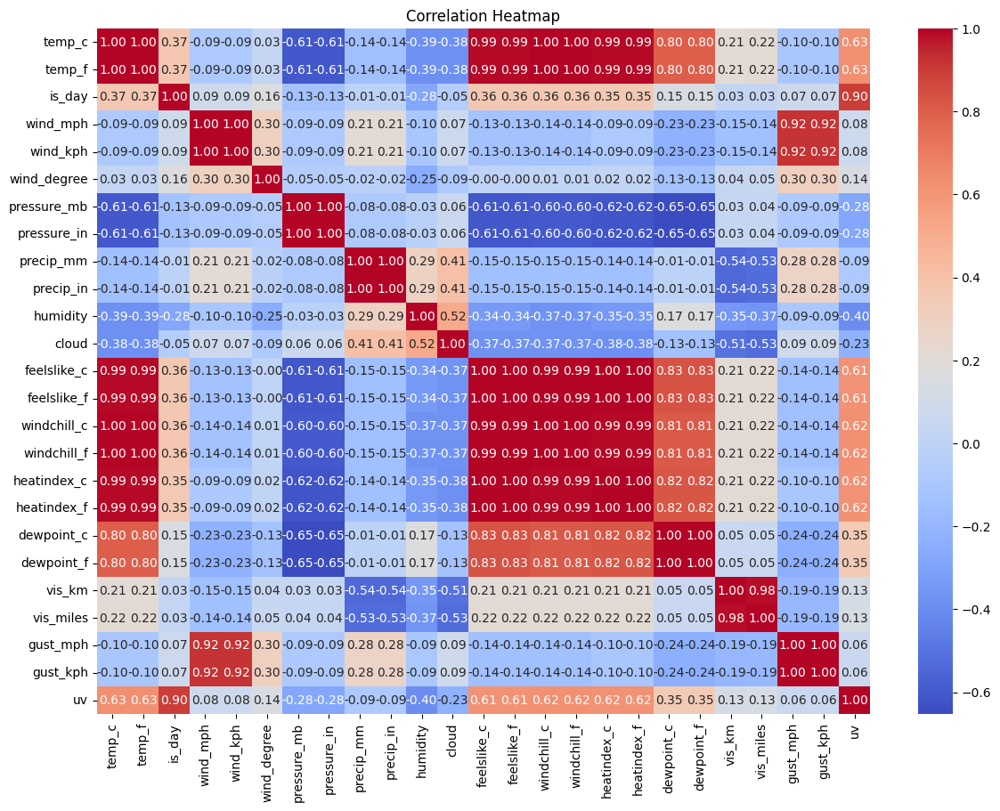

In [ ]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Observation:** As expected, unit-duplicate columns (°C/°F, mph/kph, etc.)
show near-perfect correlation (~0.99–1.00) and are candidates to consolidate.

(`temp_c`, `feelslike_c`, `windchill_c`, `heatindex_c`)
also correlates near-perfectly with each other, suggesting little independent
signal between them for this climate.

Genuine relationships worth further investigation:
* `pressure_mb` shows a
moderately strong negative correlation with temperature variables (-0.60 to -0.65),
likely reflecting seasonal pressure patterns.
* `precip_mm` and `cloud` both
negatively correlate with `vis_km` (-0.54, -0.51), consistent with rain/cloud
reducing visibility.
* `uv` correlates strongly with `is_day` (0.90, expected)
and moderately negatively with `cloud` (-0.40), consistent with cloud cover
blocking UV radiation.

## Univariate Analysis
Examining the distribution of each key variable individually (univariate),
then reviewing overall relationships via the correlation heatmap, to
understand the data's structure before drawing conclusions.

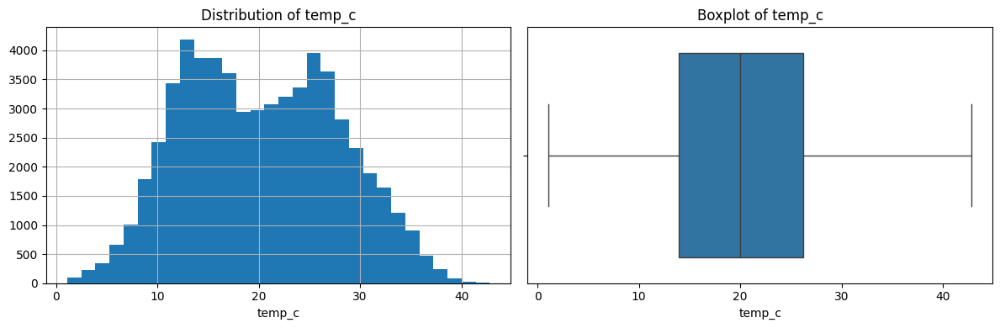

temp_c skew: 0.12



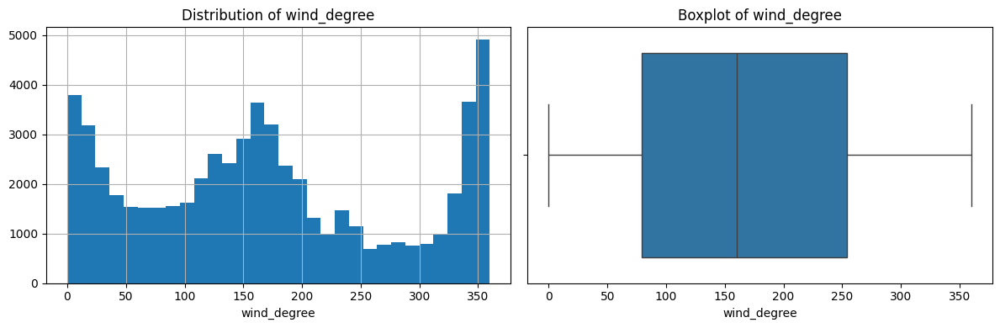

wind_degree skew: 0.25



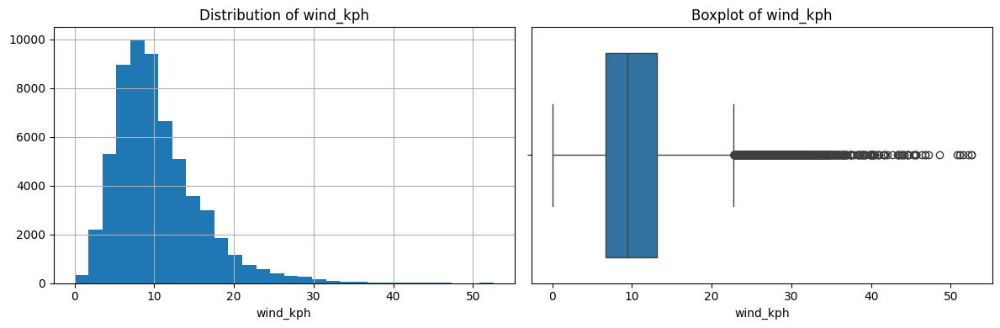

wind_kph skew: 1.39



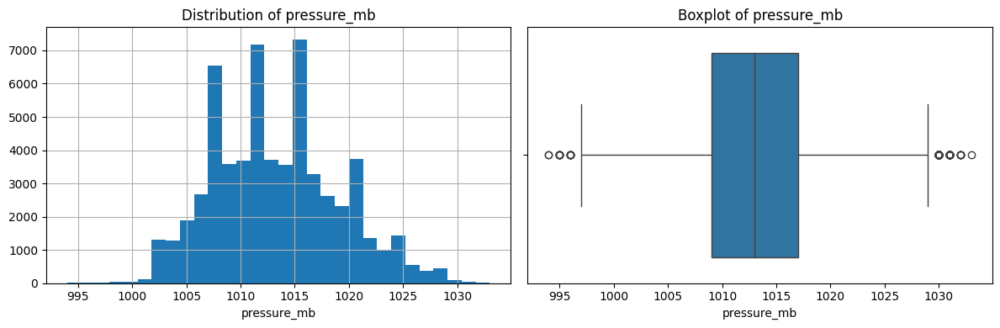

pressure_mb skew: 0.30



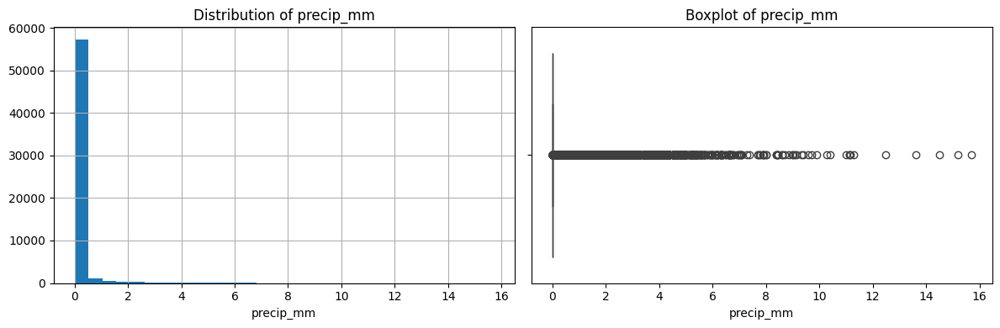

precip_mm skew: 9.20



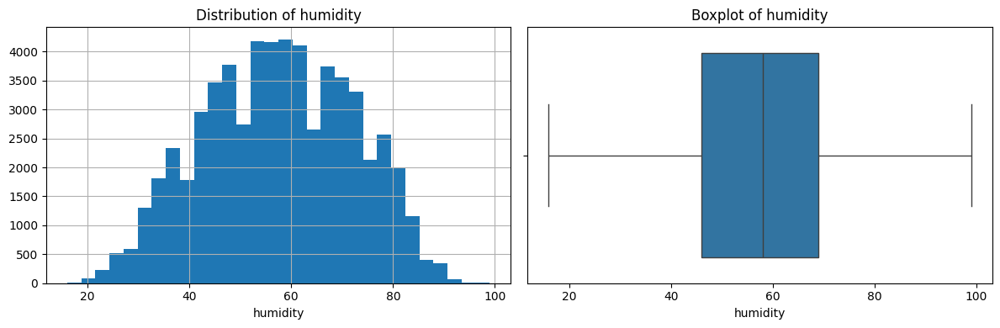

humidity skew: -0.07



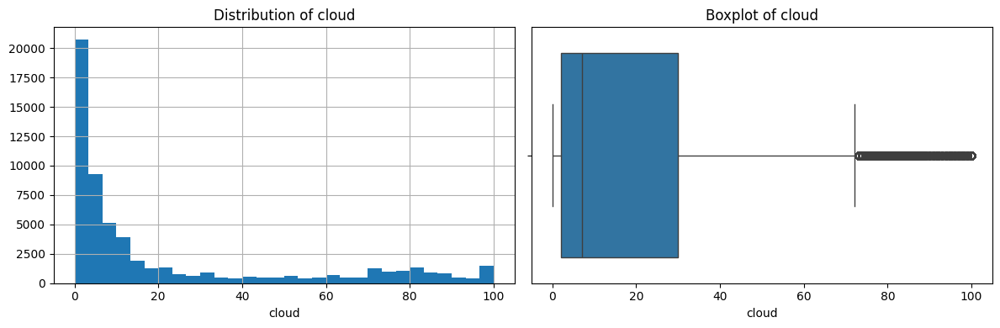

cloud skew: 1.37



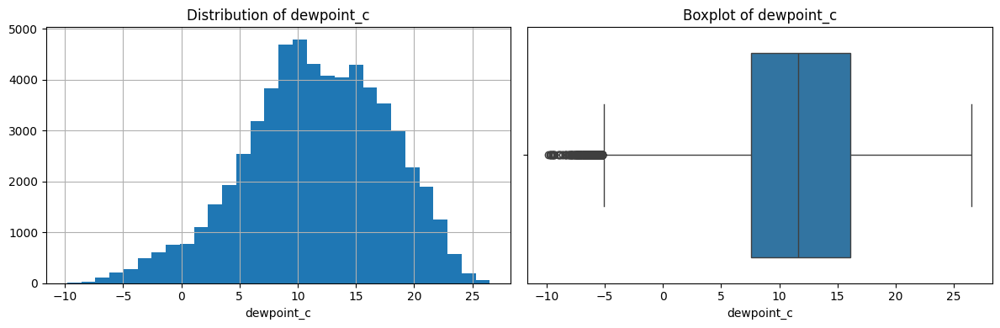

dewpoint_c skew: -0.32



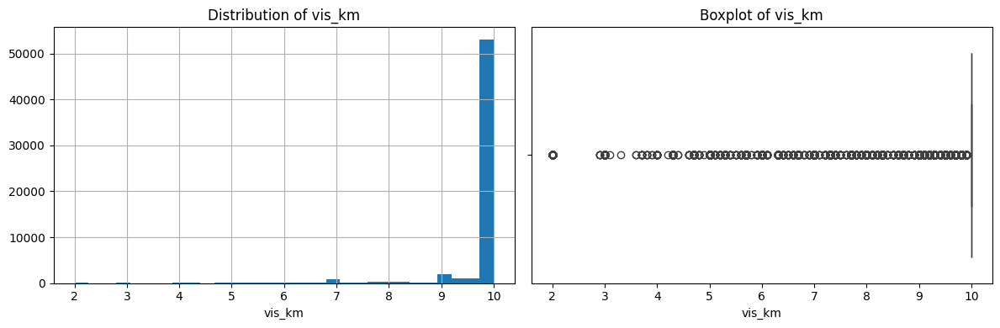

vis_km skew: -5.03



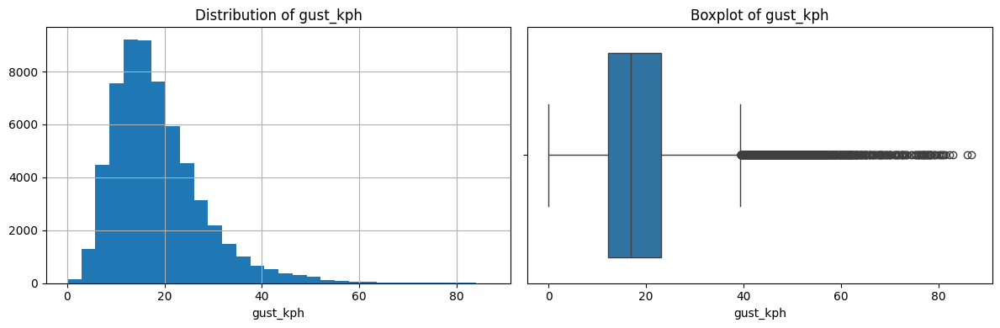

gust_kph skew: 1.44



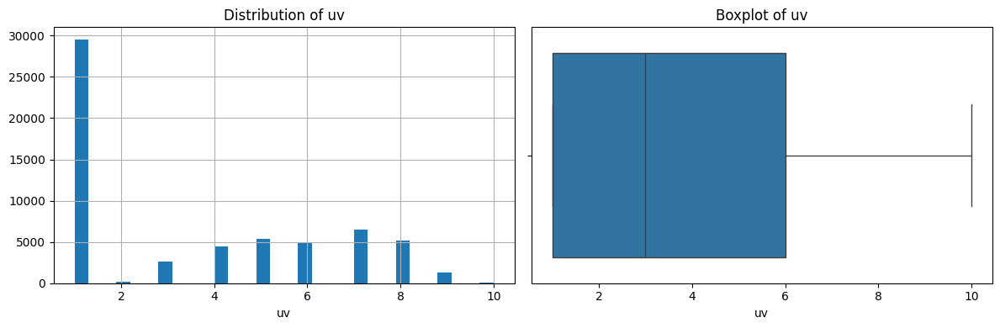

uv skew: 0.47



In [ ]:
numeric_cols = [
    'temp_c', 'wind_degree', 'wind_kph', 'pressure_mb',
    'precip_mm', 'humidity', 'cloud', 'dewpoint_c',
    'vis_km', 'gust_kph', 'uv'
]

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    df[col].hist(bins=30, ax=axes[0])
    axes[0].set_title(f'Distribution of {col}')
    axes[0].set_xlabel(col)

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f'Boxplot of {col}')

    plt.tight_layout()
    plt.show()

    print(f'{col} skew: {df[col].skew():.2f}\n')

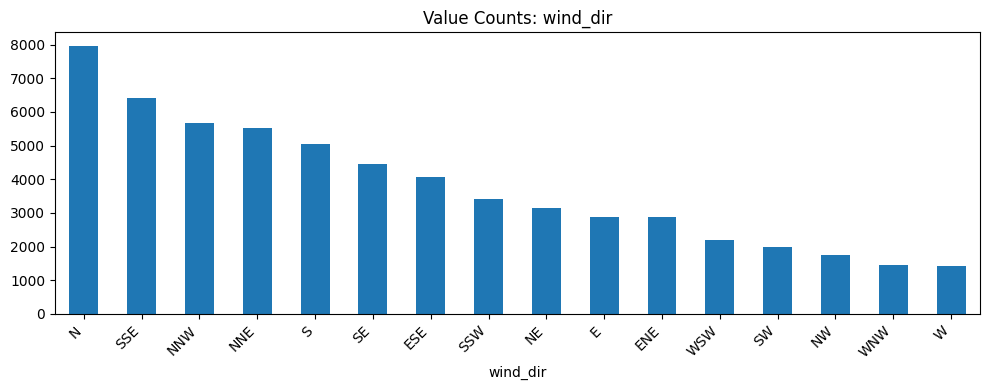

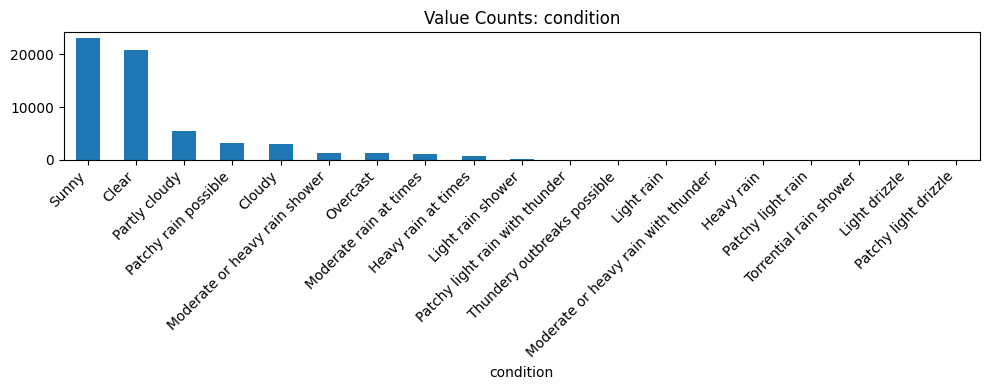

In [ ]:
categorical_cols = ['wind_dir', 'condition']

for col in categorical_cols:
    plt.figure(figsize=(10, 4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f'Value Counts: {col}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

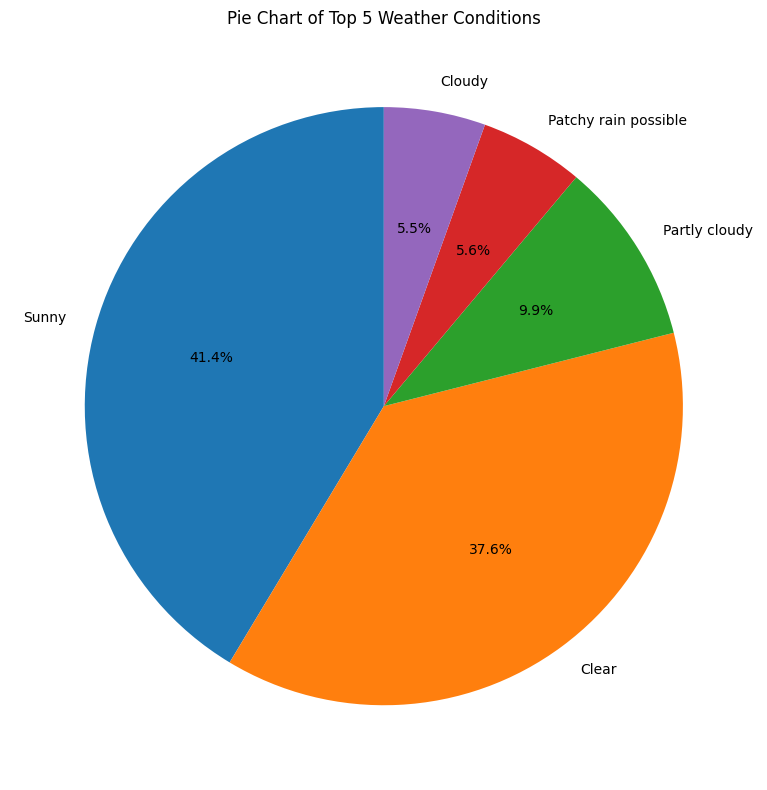

In [ ]:
top5_conditions = df['condition'].value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(top5_conditions.values, labels=top5_conditions.index, autopct='%1.1f%%', startangle=90)
plt.title('Pie Chart of Top 5 Weather Conditions')
plt.tight_layout()
plt.show()

In [ ]:
df['is_day'].value_counts()

,count
is_day,
True,30709
False,29531


**Observation:** Right-skew dominates the numeric variables, most extremely for `precip_mm` (skew 9.2) and `vis_km` (skew -5.0) — both driven by a single repeated value (0mm precipitation for most hours, a 10km visibility cap on clear days) with a long tail of rarer extremes. `wind_kph`, `cloud`, `gust_kph`, and `uv` show moderate right skew (1.3–1.4), reflecting that calm, clear conditions are the norm. `temp_c`, `wind_degree`, `pressure_mb`, and `humidity` are close to symmetric (skew -0.1 to 0.3); `temp_c` shows a mild bimodal shape from the summer/winter split. Wind is dominated by N (8,000 hours) and SSE (6,400 hours). Weather is overwhelmingly clear: `Sunny` (41.4%) and `Clear` (37.6%) together make up ~79% of all hourly readings, with rain-related conditions a small tail. `is_day` is close to balanced (30,709 day vs 29,531 night hours).

## Bivariate/Multivariate Analysis
Exploring how variables relate to each other — numeric vs numeric,
numeric vs categorical, and categorical vs categorical — building on
the patterns spotted in the correlation heatmap.

Pressure vs Temperature (r ≈ -0.61)
Confirming the negative correlation between atmospheric pressure and
temperature visually, split by weather condition.

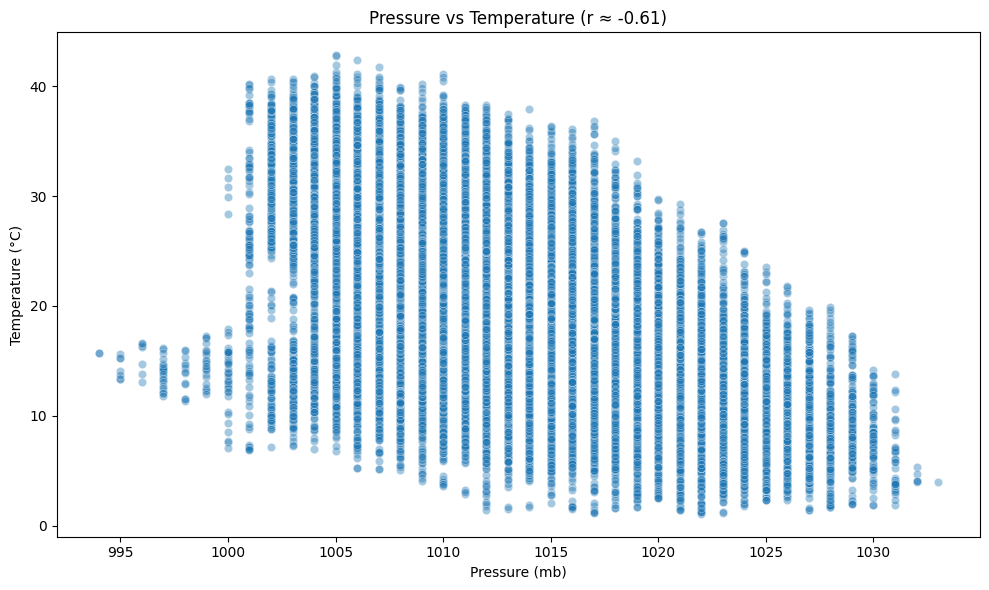

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='pressure_mb', y='temp_c', data=df, alpha=0.4)
plt.title('Pressure vs Temperature (r ≈ -0.61)')
plt.xlabel('Pressure (mb)')
plt.ylabel('Temperature (°C)')
plt.tight_layout()
plt.show()

**Observation:** Confirms the negative relationship — temperatures above 30°C occur almost only when pressure is below ~1015mb, while the coldest readings (<5°C) cluster at higher pressure (1015–1030mb), consistent with high-pressure systems bringing cooler, drier air.

Pressure vs Dewpoint (r ≈ -0.65)
Confirming the negative correlation between atmospheric pressure and
dewpoint temperature — the strongest non-duplicate relationship in the
correlation heatmap.

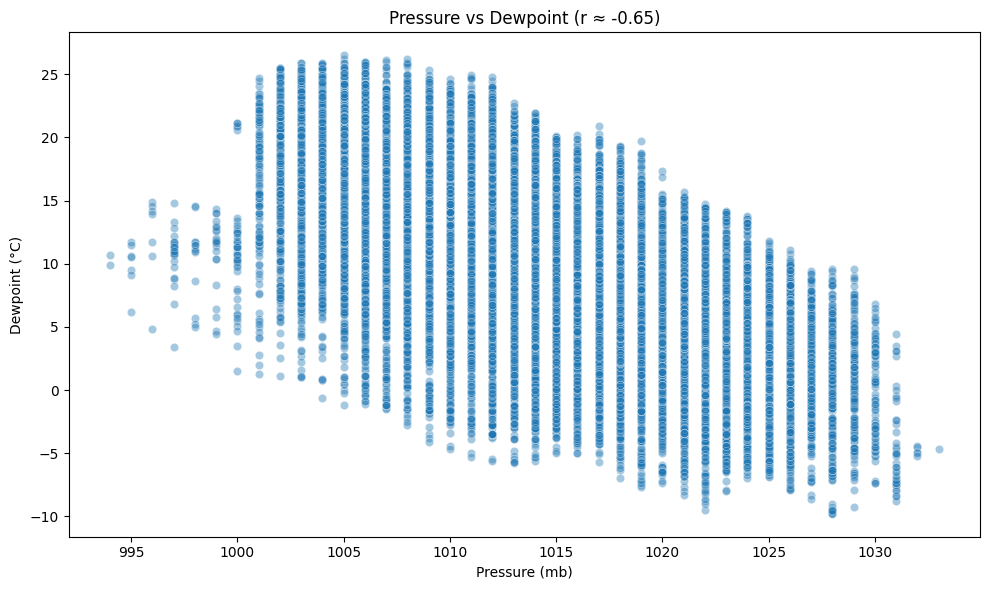

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='pressure_mb', y='dewpoint_c', data=df, alpha=0.4)
plt.title('Pressure vs Dewpoint (r ≈ -0.65)')
plt.xlabel('Pressure (mb)')
plt.ylabel('Dewpoint (°C)')
plt.tight_layout()
plt.show()

**Observation:** The strongest non-duplicate relationship in the heatmap, and it shows: dewpoint falls almost linearly from ~20–26°C at low pressure (994–1005mb) down to -5 to -10°C at high pressure (1025–1033mb) — the tightest, most linear pattern of the pressure relationships.

Precipitation vs Visibility (r ≈ -0.54)
Confirming the negative correlation between precipitation and visibility.

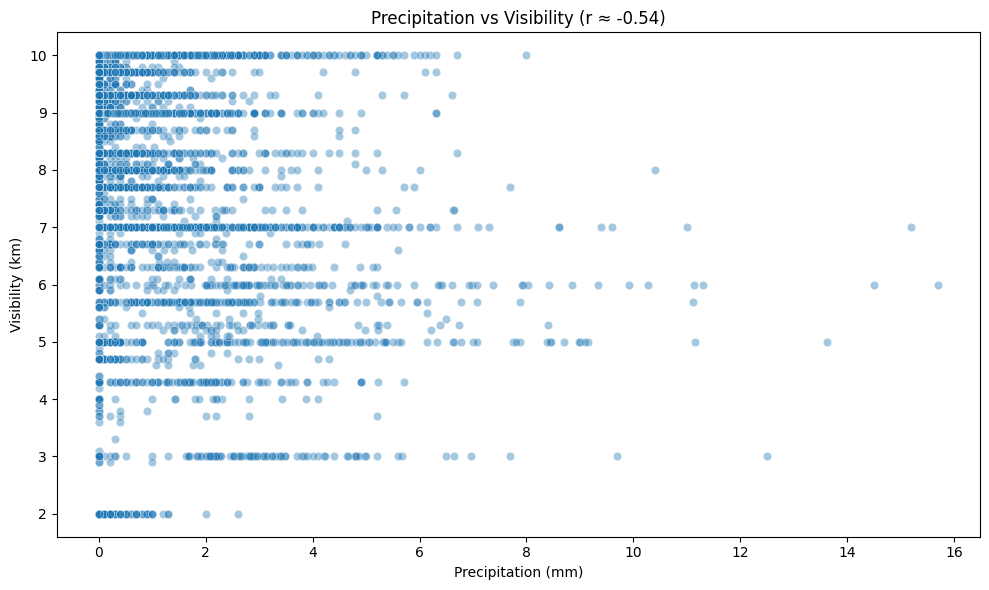

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='precip_mm', y='vis_km', data=df, alpha=0.4)
plt.title('Precipitation vs Visibility (r ≈ -0.54)')
plt.xlabel('Precipitation (mm)')
plt.ylabel('Visibility (km)')
plt.tight_layout()
plt.show()

**Observation:** This is really a ceiling effect rather than a straight-line trend: the large majority of hours have zero precipitation and span the full 2–10km visibility range, but as `precip_mm` rises, the *maximum* achievable visibility drops sharply — visibility above 8km essentially disappears once precip exceeds ~5mm, and the handful of highest-precip hours (10–16mm) cap out at 5–7km.

Cloud vs Visibility (r ≈ -0.51)
Confirming the negative correlation between cloud cover and visibility.

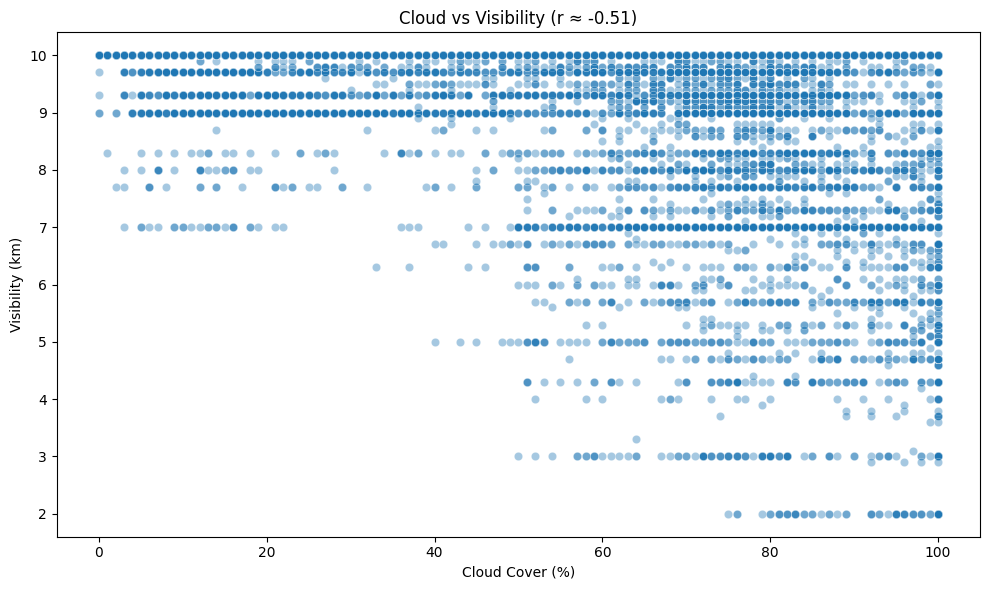

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='cloud', y='vis_km', data=df, alpha=0.4)
plt.title('Cloud vs Visibility (r ≈ -0.51)')
plt.xlabel('Cloud Cover (%)')
plt.ylabel('Visibility (km)')
plt.tight_layout()
plt.show()

**Observation:** Same ceiling-effect pattern as precipitation: full 2–10km visibility is possible even under high cloud cover, but the lowest readings (2–4km) only appear once cloud cover exceeds 50–75%. Cloud cover looks like a necessary-but-not-sufficient condition for reduced visibility, not a direct driver of it.

Humidity vs Cloud (r ≈ 0.52)
Confirming the positive correlation between humidity and cloud cover.

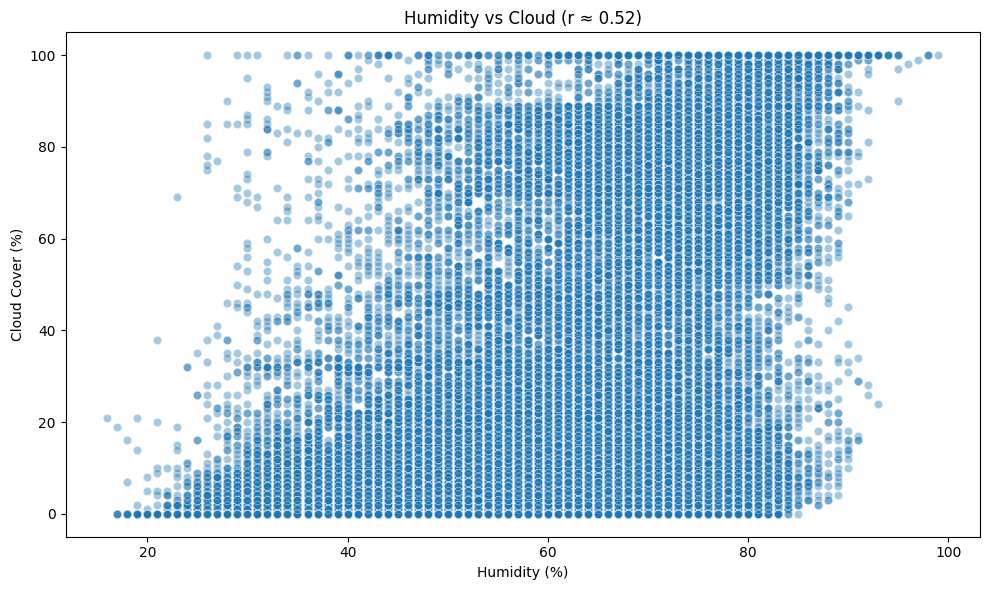

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='humidity', y='cloud', data=df, alpha=0.4)
plt.title('Humidity vs Cloud (r ≈ 0.52)')
plt.xlabel('Humidity (%)')
plt.ylabel('Cloud Cover (%)')
plt.tight_layout()
plt.show()

**Observation:** A triangular relationship rather than a linear one — below 30% humidity, cloud cover is capped near 0–20%, but above 50% humidity, cloud cover can be anywhere from 0–100%. Humidity looks necessary but not sufficient for cloud formation, which dilutes the linear correlation.

Temperature vs Dewpoint (r ≈ 0.80)
Confirming the strong positive correlation between temperature and dewpoint.

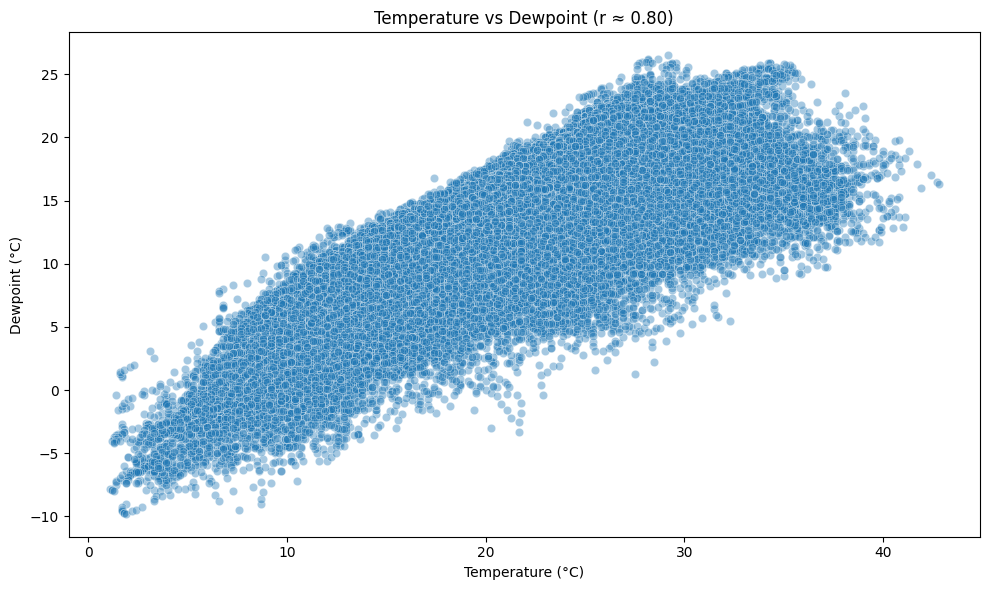

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='temp_c', y='dewpoint_c', data=df, alpha=0.4)
plt.title('Temperature vs Dewpoint (r ≈ 0.80)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Dewpoint (°C)')
plt.tight_layout()
plt.show()

**Observation:** The cleanest, most linear bivariate relationship in the dataset — dewpoint tracks temperature closely across the full range, which is physically expected since dewpoint can't exceed air temperature. The gap between the two (a dryness proxy) widens somewhat at the hottest readings (>35°C).

Cloud vs UV (r ≈ -0.40)
Confirming the negative correlation between cloud cover and UV index.

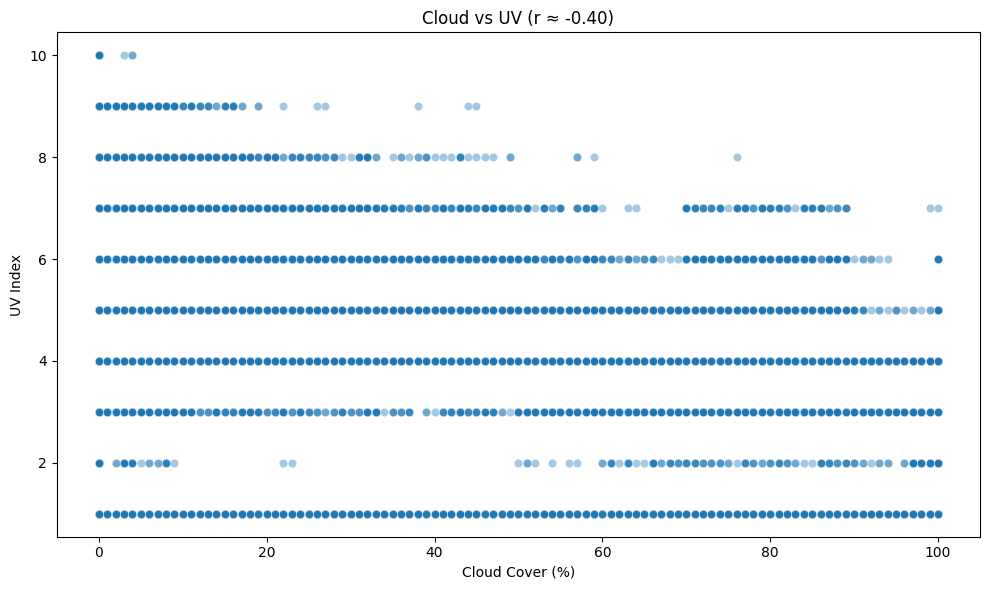

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='cloud', y='uv', data=df, alpha=0.4)
plt.title('Cloud vs UV (r ≈ -0.40)')
plt.xlabel('Cloud Cover (%)')
plt.ylabel('UV Index')
plt.tight_layout()
plt.show()

**Observation:** The correlation is driven mainly by the upper end: high UV (7–10) only occurs at low cloud cover (<40%), consistent with clear skies enabling full UV exposure. But low UV values (1–3) appear across the *entire* 0–100% cloud range — mostly because uv=1 by default at night regardless of sky condition — which dilutes the overall linear correlation (confirmed later by the hour x month UV heatmap).

## Yearly
Comparing temperature, humidity, wind speed, and precipitation across all
years side-by-side, using subplots so patterns across categories can be
compared at a glance.

In [ ]:
df['year'] = df['time'].dt.year
df['month'] = df['time'].dt.month
df['hour'] = df['time'].dt.hour

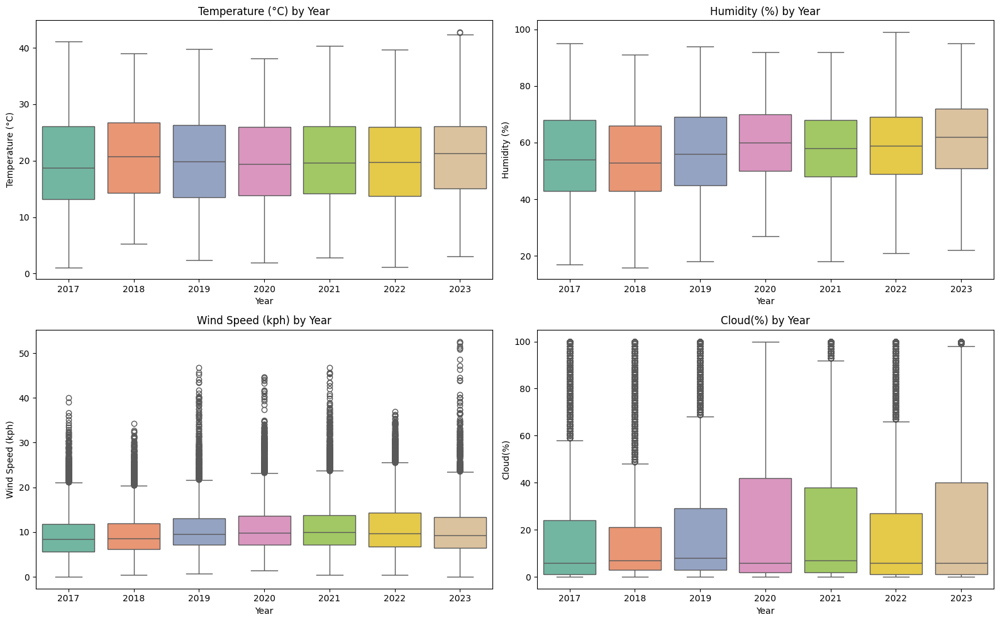

In [ ]:
variables = [
    ('temp_c', 'Temperature (°C)'),
    ('humidity', 'Humidity (%)'),
    ('wind_kph', 'Wind Speed (kph)'),
    ('cloud', 'Cloud(%)')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, (col, ylabel) in zip(axes, variables):
    sns.boxplot(x='year', y=col, hue='year', data=df, ax=ax, palette='Set2', legend=False)
    ax.set_title(f'{ylabel} by Year')
    ax.set_xlabel('Year')
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()

In [ ]:
yearly_summary = df.groupby('year')[['temp_c', 'humidity', 'wind_kph', 'pressure_mb']].describe()
yearly_summary.T

year                      2017         2018         2019         2020  \
temp_c      count  8736.000000  8760.000000  8760.000000  8784.000000   
            mean     19.470272    20.828607    20.138459    20.108436   
            std       8.030543     7.378292     7.520340     7.573853   
            min       1.100000     5.300000     2.400000     1.900000   
            25%      13.200000    14.300000    13.500000    13.800000   
            50%      18.700000    20.800000    19.900000    19.400000   
            75%      26.100000    26.800000    26.300000    26.000000   
            max      41.100000    39.000000    39.800000    38.100000   
humidity    count  8736.000000  8760.000000  8760.000000  8784.000000   
            mean     55.413118    54.097831    56.452055    59.546220   
            std      16.040526    15.426653    15.581728    13.136152   
            min      17.000000    16.000000    18.000000    27.000000   
            25%      43.000000    43.000000    45.000000    50.000000   
            50%      54.000000    53.000000    56.000000    60.000000   
            75%      68.000000    66.000000    69.000000    70.000000   
            max      95.000000    91.000000    94.000000    92.000000   
wind_kph    count  8736.000000  8760.000000  8760.000000  8784.000000   
            mean      9.303926     9.538242    10.642648    10.996107   
            std       5.116334     4.757204     5.062236     5.468174   
            min       0.000000     0.400000     0.700000     1.400000   
            25%       5.600000     6.200000     7.200000     7.200000   
            50%       8.400000     8.600000     9.600000     9.800000   
            75%      11.800000    11.900000    13.000000    13.600000   
            max      40.100000    34.300000    46.800000    44.700000   
pressure_mb count  8736.000000  8760.000000  8760.000000  8784.000000   
            mean   1014.864469  1013.330137  1013.379224  1013.285974   
            std       5.556697     5.519328     5.139077     5.788834   
            min    1002.000000   994.000000   995.000000  1000.000000   
            25%    1011.000000  1009.000000  1010.000000  1008.000000   
            50%    1014.000000  1013.000000  1013.000000  1013.000000   
            75%    1019.000000  1017.000000  1017.000000  1017.000000   
            max    1031.000000  1031.000000  1030.000000  1033.000000   

year                      2021         2022         2023  
temp_c      count  8760.000000  8760.000000  7680.000000  
            mean     20.256210    19.884269    20.973659  
            std       7.591929     8.009693     7.412330  
            min       2.800000     1.200000     3.100000  
            25%      14.200000    13.700000    15.100000  
            50%      19.600000    19.700000    21.300000  
            75%      26.100000    26.000000    26.100000  
            max      40.400000    39.700000    42.800000  
humidity    count  8760.000000  8760.000000  7680.000000  
            mean     57.772374    58.645434    60.708854  
            std      13.670014    13.736785    14.205389  
            min      18.000000    21.000000    22.000000  
            25%      48.000000    49.000000    51.000000  
            50%      58.000000    59.000000    62.000000  
            75%      68.000000    69.000000    72.000000  
            max      92.000000    99.000000    95.000000  
wind_kph    count  8760.000000  8760.000000  7680.000000  
            mean     11.120925    11.012306    10.362513  
            std       5.561624     5.742711     5.819753  
            min       0.400000     0.400000     0.000000  
            25%       7.200000     6.800000     6.500000  
            50%      10.000000     9.700000     9.300000  
            75%      13.800000    14.300000    13.300000  
            max      46.800000    36.900000    52.600000  
pressure_mb count  8760.000000  8760.000000  7680.000000  
            mean   1012.977169  1012.659703  1012.167839

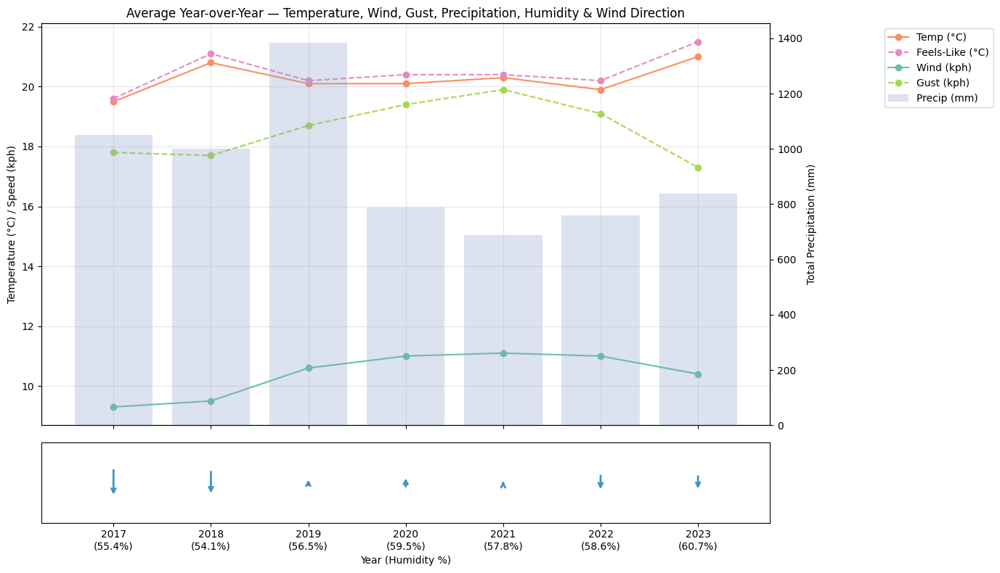

In [ ]:
import numpy as np

def circular_mean_degrees(series):
    radians = np.deg2rad(series)
    mean_sin = np.mean(np.sin(radians))
    mean_cos = np.mean(np.cos(radians))
    return (np.rad2deg(np.arctan2(mean_sin, mean_cos))) % 360

avg_year_table = df.groupby('year')[['temp_c', 'feelslike_c', 'precip_mm', 'wind_kph', 'gust_kph', 'humidity']].agg({
    'temp_c': 'mean',
    'feelslike_c': 'mean',
    'precip_mm': 'sum',
    'wind_kph': 'mean',
    'gust_kph': 'mean',
    'humidity': 'mean'
}).round(1)
avg_year_table['wind_degree'] = df.groupby('year')['wind_degree'].apply(circular_mean_degrees)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                           gridspec_kw={'height_ratios': [4, 0.8]})

# Main combined chart
ax1 = axes[0]
ax1.plot(avg_year_table.index, avg_year_table['temp_c'], marker='o', label='Temp (°C)', color='#fc8d62')
ax1.plot(avg_year_table.index, avg_year_table['feelslike_c'], marker='o', label='Feels-Like (°C)', color='#e78ac3', linestyle='--')
ax1.plot(avg_year_table.index, avg_year_table['wind_kph'], marker='o', label='Wind (kph)', color='#66c2a5')
ax1.plot(avg_year_table.index, avg_year_table['gust_kph'], marker='o', label='Gust (kph)', color='#a6d854', linestyle='--')
ax1.set_ylabel('Temperature (°C) / Speed (kph)')
ax1.set_title('Average Year-over-Year — Temperature, Wind, Gust, Precipitation, Humidity & Wind Direction')
ax1.grid(alpha=0.3)

# x-axis ticks: year + humidity underneath
xtick_labels = [f'{y}\n({hum}%)' for y, hum in zip(avg_year_table.index, avg_year_table['humidity'])]
ax1.set_xticks(avg_year_table.index)
ax1.set_xticklabels(xtick_labels, fontsize=9)

ax2 = ax1.twinx()
ax2.bar(avg_year_table.index, avg_year_table['precip_mm'], alpha=0.3, color='#8da0cb', label='Precip (mm)')
ax2.set_ylabel('Total Precipitation (mm)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', bbox_to_anchor=(1.15, 1))

# Wind direction arrow row
for y, deg in zip(avg_year_table.index, avg_year_table['wind_degree']):
    dx = np.sin(np.deg2rad(deg + 180))
    dy = np.cos(np.deg2rad(deg + 180))
    axes[1].annotate('', xy=(y, dy*0.4), xytext=(y, -dy*0.4),
                       arrowprops=dict(arrowstyle='->', color='#4292c6', lw=2))
axes[1].set_ylim(-1, 1)
axes[1].set_yticks([])
axes[1].set_xlabel('Year (Humidity %)')

plt.tight_layout()
plt.show()

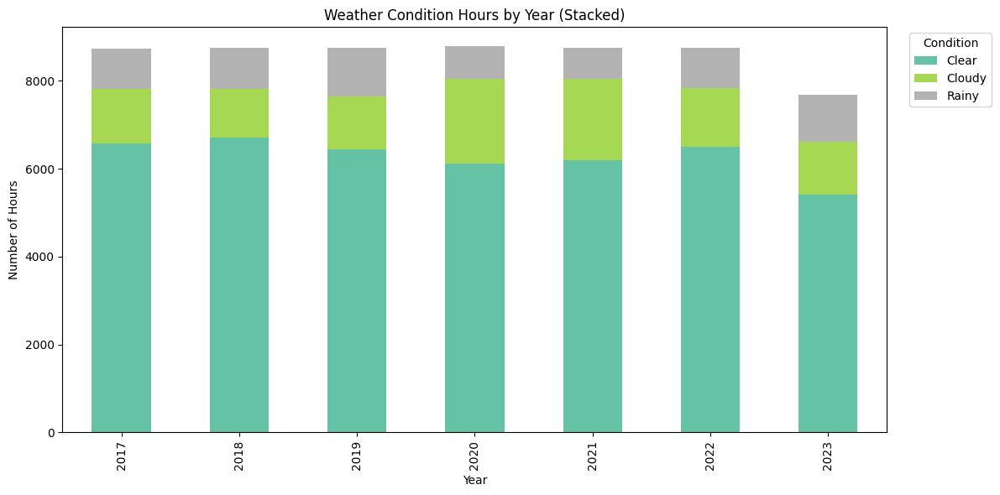

In [ ]:
def simplify_condition(cond):
    cond = cond.lower()
    if 'rain' in cond or 'drizzle' in cond or 'thunder' in cond:
        return 'Rainy'
    elif 'cloud' in cond or 'overcast' in cond:
        return 'Cloudy'
    elif 'sunny' in cond or 'clear' in cond:
        return 'Clear'
    else:
        return 'Other'

df['condition_group'] = df['condition'].apply(simplify_condition)
df['condition_group'].value_counts()
condition_by_year = df.groupby(['year', 'condition_group']).size().unstack()

condition_by_year.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='Set2')
plt.title('Weather Condition Hours by Year (Stacked)')
plt.xlabel('Year')
plt.ylabel('Number of Hours')
plt.legend(title='Condition', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

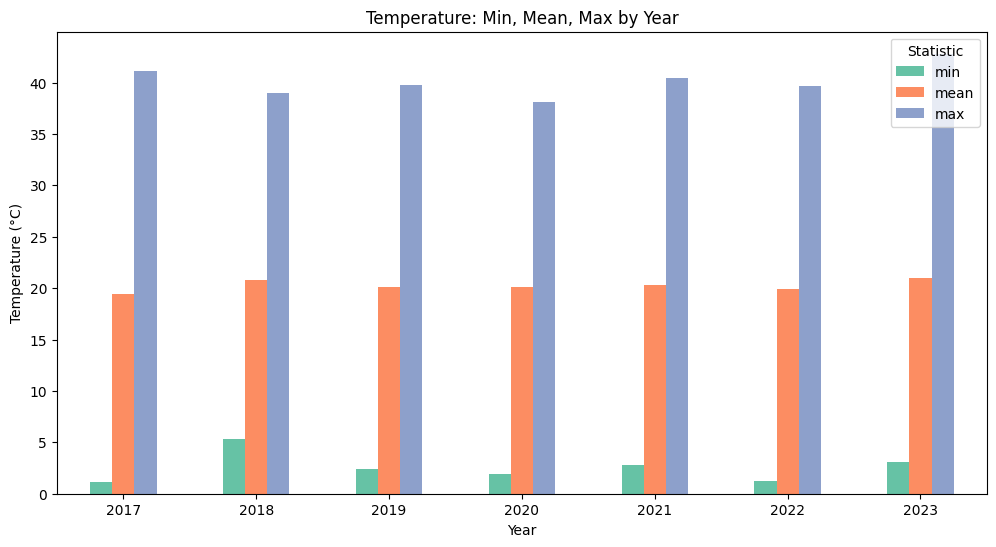

In [ ]:
yearly_summary = df.groupby('year')['temp_c'].agg(['min', 'mean', 'max'])

yearly_summary.plot(kind='bar', figsize=(12, 6), color=['#66c2a5', '#fc8d62', '#8da0cb'])
plt.title('Temperature: Min, Mean, Max by Year')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend(title='Statistic')
plt.xticks(rotation=0)
plt.show()

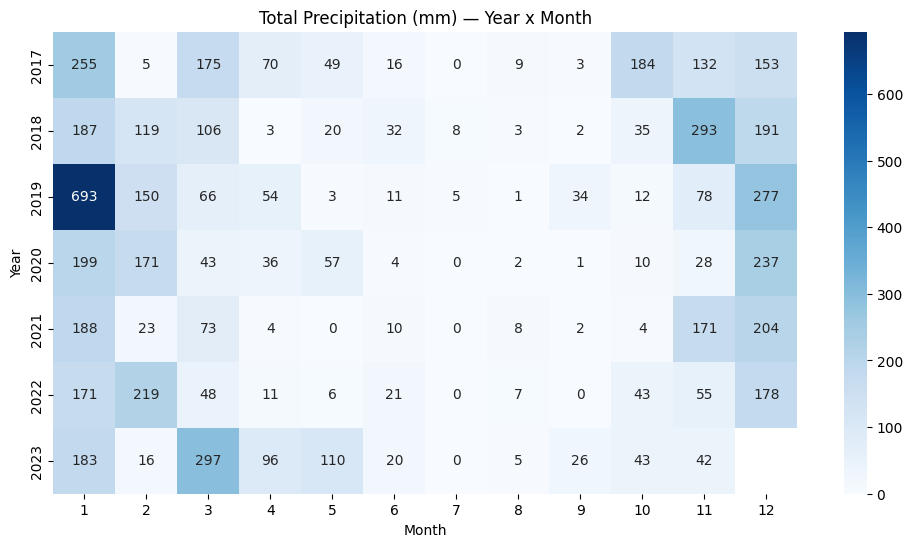

In [ ]:
year_month_precip = df.groupby(['year', 'month'])['precip_mm'].sum().unstack()

plt.figure(figsize=(12, 6))
sns.heatmap(year_month_precip, annot=True, fmt='.0f', cmap='Blues')
plt.title('Total Precipitation (mm) — Year x Month')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

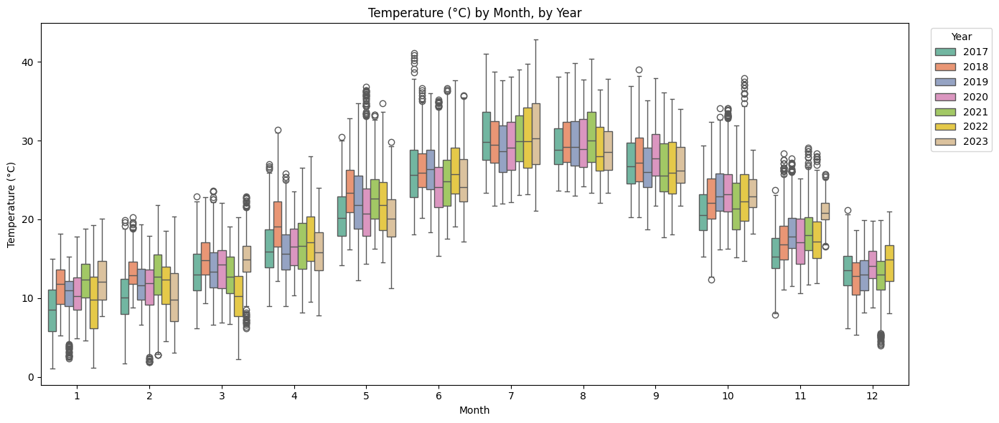

In [ ]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='month', y='temp_c', hue='year', data=df, palette='Set2')
plt.title('Temperature (°C) by Month, by Year')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

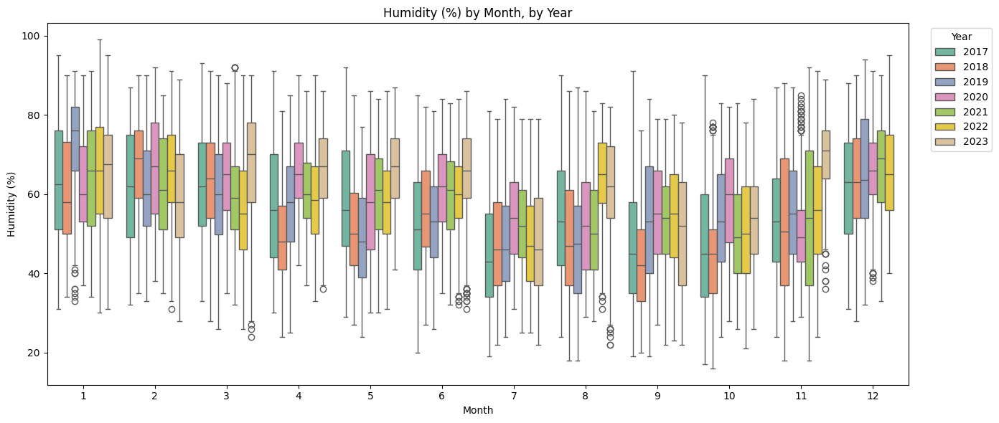

In [ ]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='month', y='humidity', hue='year', data=df, palette='Set2')
plt.title('Humidity (%) by Month, by Year')
plt.xlabel('Month')
plt.ylabel('Humidity (%)')
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

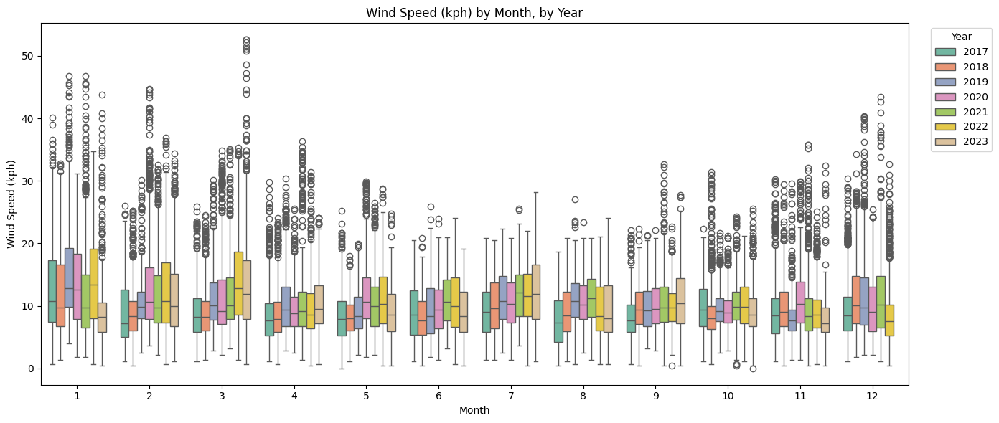

In [ ]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='month', y='wind_kph', hue='year', data=df, palette='Set2')
plt.title('Wind Speed (kph) by Month, by Year')
plt.xlabel('Month')
plt.ylabel('Wind Speed (kph)')
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Observation:** Year-to-year, the climate is remarkably stable: temperature, humidity, and wind-speed medians barely move across 2017–2023, though 2020 stands out with higher median cloud cover and 2023 (a partial year, through Nov 16) shows the widest temperature range (max 42.8°C) and highest average humidity (60.7%). Wind and gust speed rose gradually from 9kph (2017–18) to 11kph (2019–2022) before easing back in 2023. `Clear` conditions dominate every year (6,000–6,700 of 8,760 hours), with `Cloudy` hours jumping noticeably in 2020. Precipitation is dominated by a single extreme month — January 2019 (693mm, vs typically <300mm/month) — otherwise July is bone-dry in every single year (0mm), confirming a hard Mediterranean dry-summer pattern that holds across all 7 years.

## Monthly
Examining the overall seasonal pattern across months, combining all
years together — spread and outliers per month, the seasonal trend
line, and total precipitation by month.

In [ ]:
monthly_summary = df.groupby('month')['temp_c'].agg(['min', 'mean', 'max'])

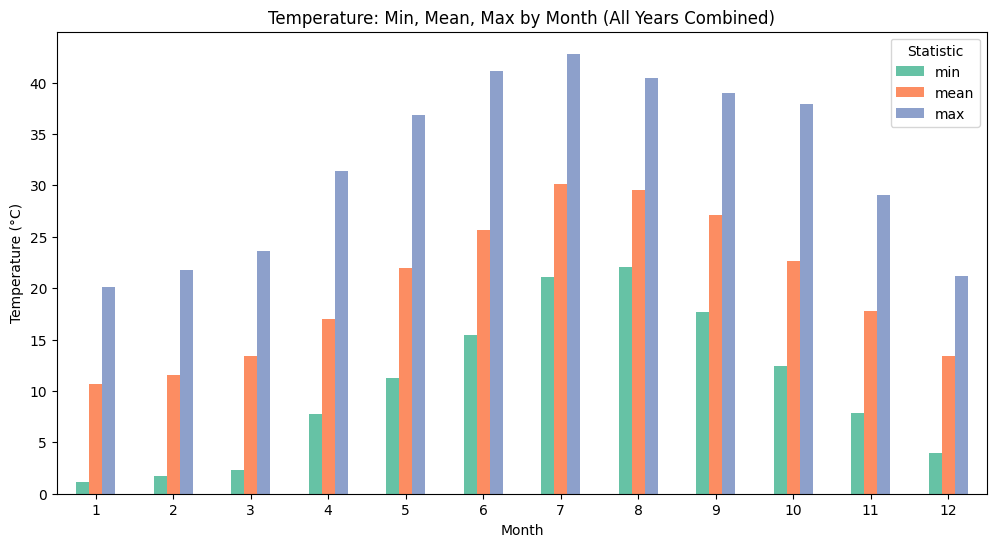

In [ ]:
monthly_summary.plot(kind='bar', figsize=(12, 6), color=['#66c2a5', '#fc8d62', '#8da0cb'])
plt.title('Temperature: Min, Mean, Max by Month (All Years Combined)')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.legend(title='Statistic')
plt.xticks(rotation=0)
plt.show()

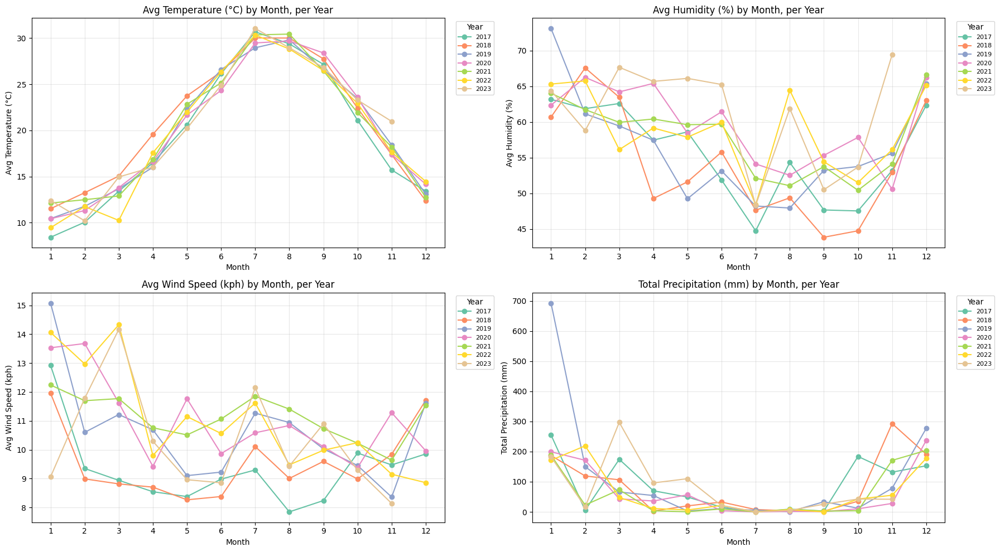

In [ ]:
years = sorted(df['year'].unique())
palette = sns.color_palette('Set2', n_colors=len(years))

variables = [
    ('temp_c', 'mean', 'Avg Temperature (°C)'),
    ('humidity', 'mean', 'Avg Humidity (%)'),
    ('wind_kph', 'mean', 'Avg Wind Speed (kph)'),
    ('precip_mm', 'sum', 'Total Precipitation (mm)')
]

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

for ax, (col, agg, ylabel) in zip(axes, variables):
    monthly_by_year = df.groupby(['year', 'month'])[col].agg(agg).unstack(level=0)
    monthly_by_year.plot(marker='o', ax=ax, color=palette)
    ax.set_title(f'{ylabel} by Month, per Year')
    ax.set_xlabel('Month')
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

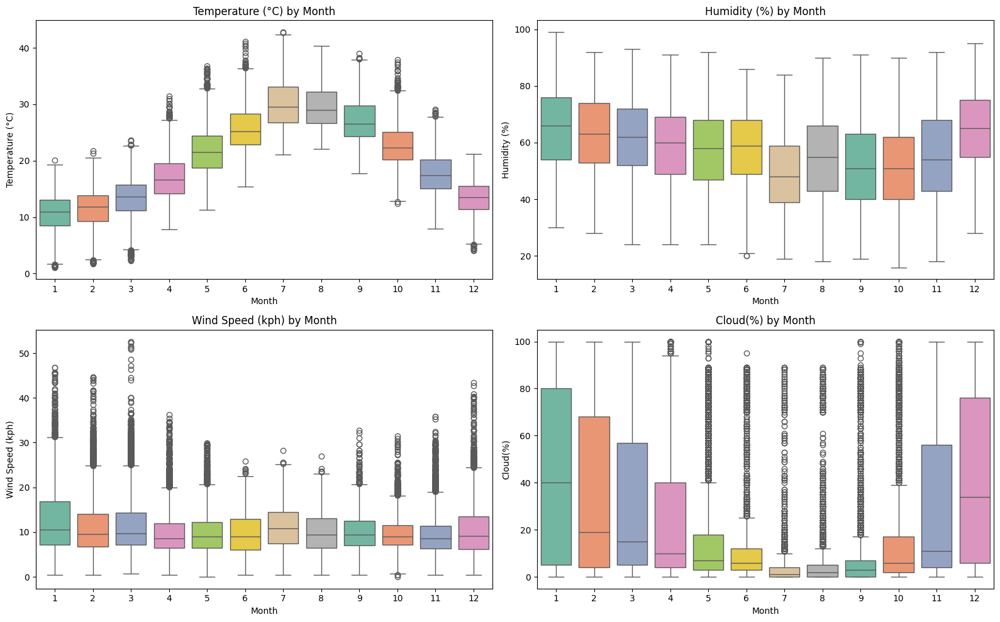

In [ ]:
variables = [
    ('temp_c', 'Temperature (°C)'),
    ('humidity', 'Humidity (%)'),
    ('wind_kph', 'Wind Speed (kph)'),
    ('cloud', 'Cloud(%)')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, (col, ylabel) in zip(axes, variables):
    sns.boxplot(x='month', y=col, hue='month', data=df, ax=ax, palette='Set2', legend=False)
    ax.set_title(f'{ylabel} by Month')
    ax.set_xlabel('Month')
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()

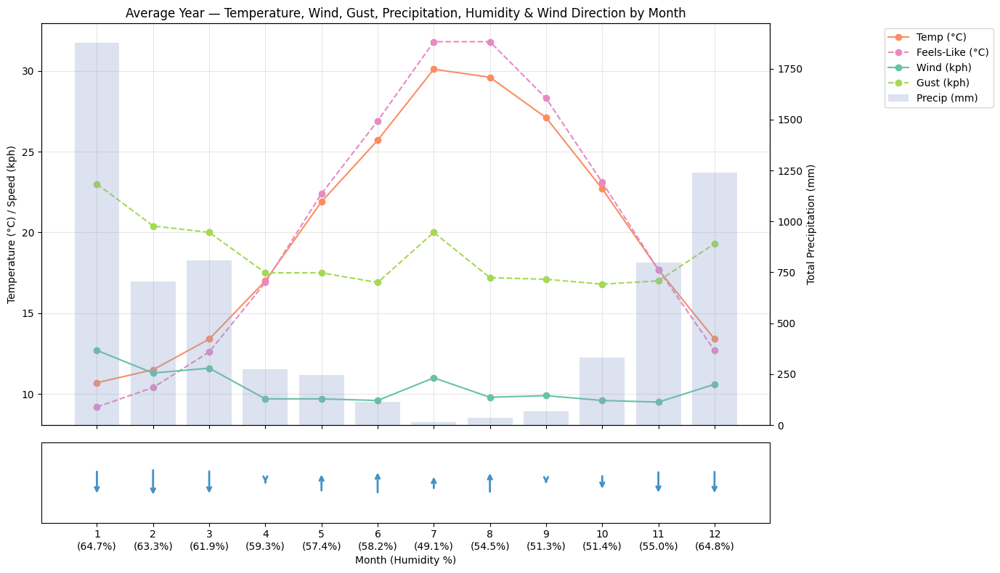

In [ ]:
def circular_mean_degrees(series):
    radians = np.deg2rad(series)
    mean_sin = np.mean(np.sin(radians))
    mean_cos = np.mean(np.cos(radians))
    return (np.rad2deg(np.arctan2(mean_sin, mean_cos))) % 360

avg_month_table = df.groupby('month')[['temp_c', 'feelslike_c', 'precip_mm', 'wind_kph', 'gust_kph', 'humidity']].agg({
    'temp_c': 'mean',
    'feelslike_c': 'mean',
    'precip_mm': 'sum',
    'wind_kph': 'mean',
    'gust_kph': 'mean',
    'humidity': 'mean'
}).round(1)
avg_month_table['wind_degree'] = df.groupby('month')['wind_degree'].apply(circular_mean_degrees)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                           gridspec_kw={'height_ratios': [4, 0.8]})

# Main combined chart
ax1 = axes[0]
ax1.plot(avg_month_table.index, avg_month_table['temp_c'], marker='o', label='Temp (°C)', color='#fc8d62')
ax1.plot(avg_month_table.index, avg_month_table['feelslike_c'], marker='o', label='Feels-Like (°C)', color='#e78ac3', linestyle='--')
ax1.plot(avg_month_table.index, avg_month_table['wind_kph'], marker='o', label='Wind (kph)', color='#66c2a5')
ax1.plot(avg_month_table.index, avg_month_table['gust_kph'], marker='o', label='Gust (kph)', color='#a6d854', linestyle='--')
ax1.set_ylabel('Temperature (°C) / Speed (kph)')
ax1.set_title('Average Year — Temperature, Wind, Gust, Precipitation, Humidity & Wind Direction by Month')
ax1.grid(alpha=0.3)

# x-axis ticks: month number + humidity underneath
xtick_labels = [f'{m}\n({h}%)' for m, h in zip(avg_month_table.index, avg_month_table['humidity'])]
ax1.set_xticks(avg_month_table.index)
ax1.set_xticklabels(xtick_labels)

ax2 = ax1.twinx()
ax2.bar(avg_month_table.index, avg_month_table['precip_mm'], alpha=0.3, color='#8da0cb', label='Precip (mm)')
ax2.set_ylabel('Total Precipitation (mm)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', bbox_to_anchor=(1.15, 1))

# Wind direction arrow row
for m, deg in zip(avg_month_table.index, avg_month_table['wind_degree']):
    dx = np.sin(np.deg2rad(deg + 180))
    dy = np.cos(np.deg2rad(deg + 180))
    axes[1].annotate('', xy=(m, dy*0.4), xytext=(m, -dy*0.4),
                       arrowprops=dict(arrowstyle='->', color='#4292c6', lw=2))
axes[1].set_ylim(-1, 1)
axes[1].set_yticks([])
axes[1].set_xlabel('Month (Humidity %)')

plt.tight_layout()
plt.show()

**Observation:** A textbook Mediterranean seasonal cycle: mean temperature rises from 11°C in January to a 30°C peak in July/August, while `feels-like` temperature exceeds actual temperature by the most in summer (humidity-driven, e.g. 30.1°C actual vs 31.8°C feels-like in July) rather than in winter. Precipitation is concentrated Nov–Mar and essentially zero Jun–Sep across all years (the per-year lines all collapse near 0 in summer). Humidity is highest in Jan/Dec (65%) and lowest in July (49%), while wind and gust speed are higher in winter (gust 23kph in Jan) than summer (20kph in Jul). The month-by-year boxplots show this seasonal shape is highly consistent — summer months cluster tightly across years, while winter months (Jan–Mar, Nov–Dec) show noticeably more year-to-year spread.

## Daily
Examining how temperature, humidity, wind speed, and UV vary across
the hours of the day, to understand the daily (diurnal) cycle.

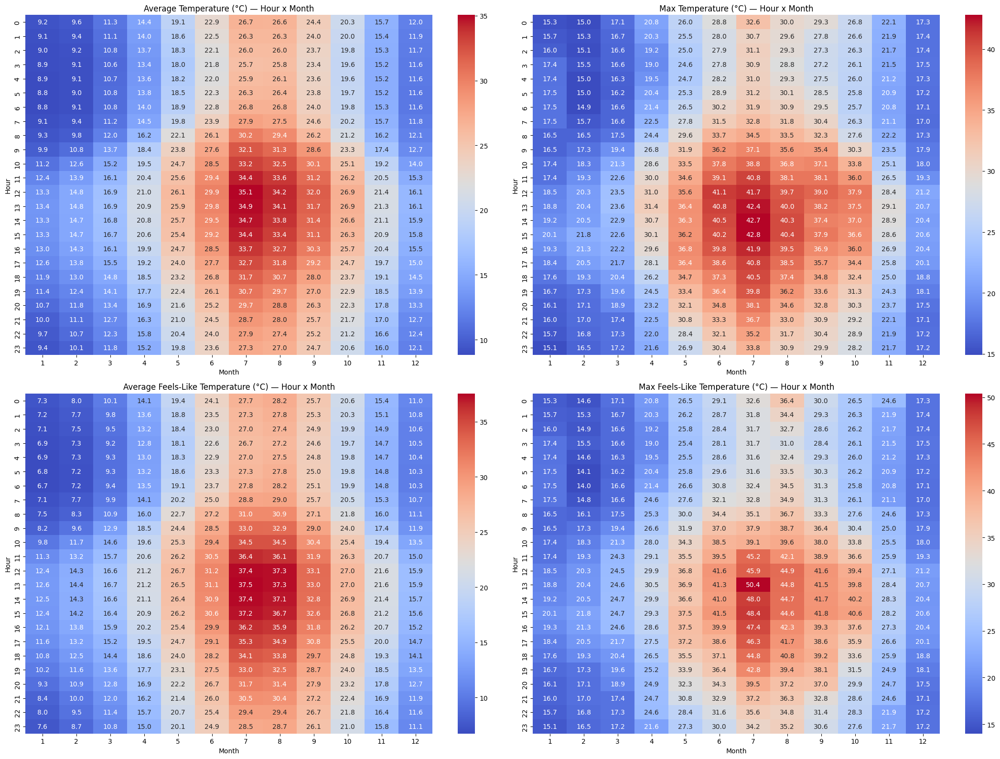

In [ ]:
hour_month_temp_mean = df.groupby(['hour', 'month'])['temp_c'].mean().unstack()
hour_month_temp_max = df.groupby(['hour', 'month'])['temp_c'].max().unstack()
hour_month_feelslike_mean = df.groupby(['hour', 'month'])['feelslike_c'].mean().unstack()
hour_month_feelslike_max = df.groupby(['hour', 'month'])['feelslike_c'].max().unstack()

fig, axes = plt.subplots(2, 2, figsize=(22, 16))

sns.heatmap(hour_month_temp_mean, annot=True, fmt='.1f', cmap='coolwarm', ax=axes[0,0])
axes[0,0].set_title('Average Temperature (°C) — Hour x Month')
axes[0,0].set_xlabel('Month')
axes[0,0].set_ylabel('Hour')

sns.heatmap(hour_month_temp_max, annot=True, fmt='.1f', cmap='coolwarm', ax=axes[0,1])
axes[0,1].set_title('Max Temperature (°C) — Hour x Month')
axes[0,1].set_xlabel('Month')
axes[0,1].set_ylabel('Hour')

sns.heatmap(hour_month_feelslike_mean, annot=True, fmt='.1f', cmap='coolwarm', ax=axes[1,0])
axes[1,0].set_title('Average Feels-Like Temperature (°C) — Hour x Month')
axes[1,0].set_xlabel('Month')
axes[1,0].set_ylabel('Hour')

sns.heatmap(hour_month_feelslike_max, annot=True, fmt='.1f', cmap='coolwarm', ax=axes[1,1])
axes[1,1].set_title('Max Feels-Like Temperature (°C) — Hour x Month')
axes[1,1].set_xlabel('Month')
axes[1,1].set_ylabel('Hour')

plt.tight_layout()
plt.show()

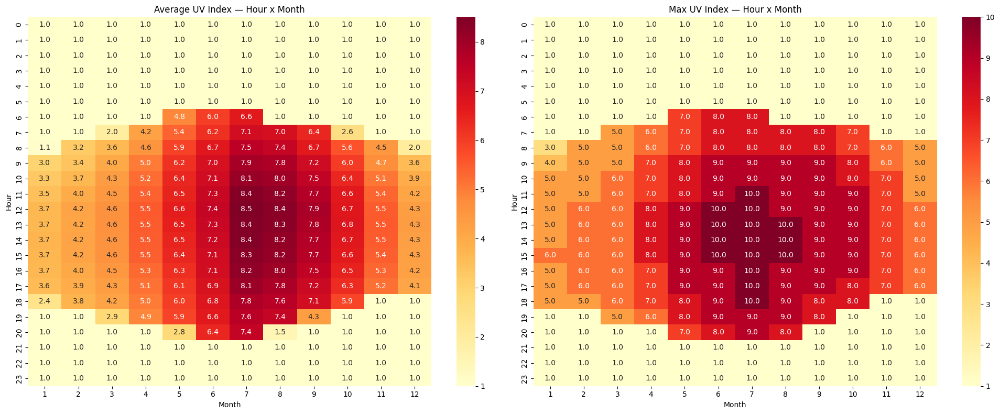

In [ ]:
hour_month_uv_mean = df.groupby(['hour', 'month'])['uv'].mean().unstack()
hour_month_uv_max = df.groupby(['hour', 'month'])['uv'].max().unstack()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(hour_month_uv_mean, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[0])
axes[0].set_title('Average UV Index — Hour x Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Hour')

sns.heatmap(hour_month_uv_max, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1])
axes[1].set_title('Max UV Index — Hour x Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Hour')

plt.tight_layout()
plt.show()

In [ ]:
def circular_mean_degrees(series):
    radians = np.deg2rad(series)
    mean_sin = np.mean(np.sin(radians))
    mean_cos = np.mean(np.cos(radians))
    mean_angle = np.rad2deg(np.arctan2(mean_sin, mean_cos))
    return mean_angle % 360

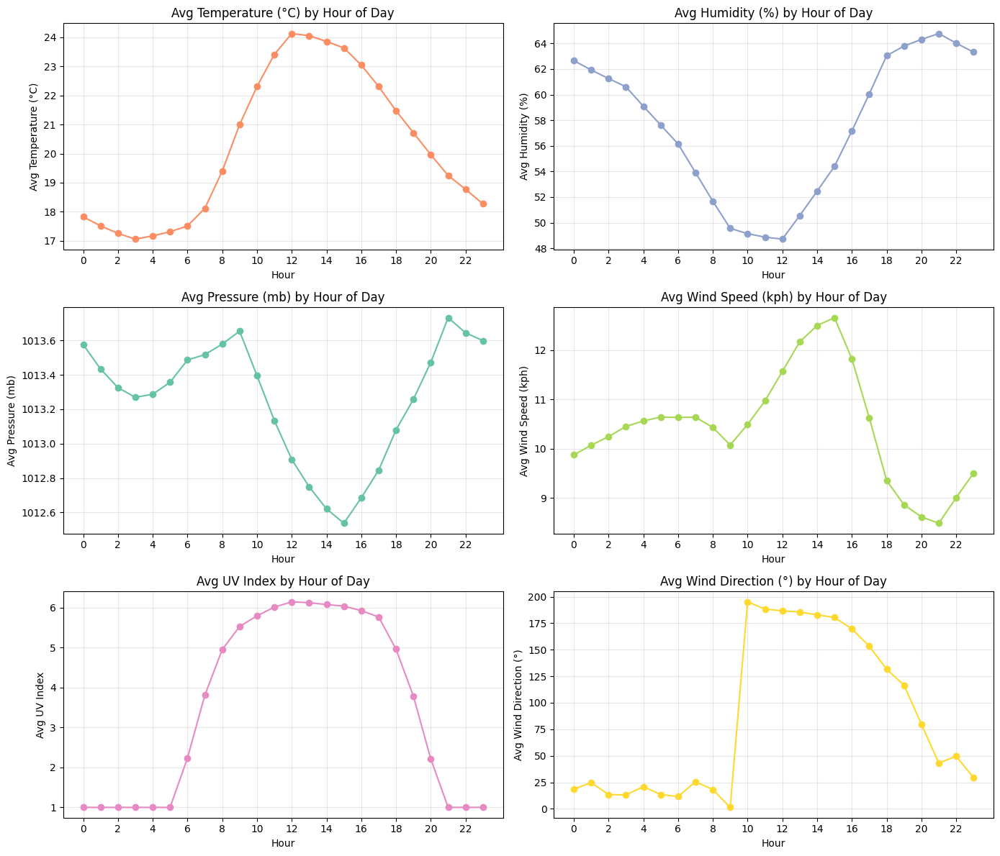

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

hourly_stats = df.groupby('hour')[['temp_c', 'humidity', 'pressure_mb', 'wind_kph', 'uv', 'is_day']].mean()
hourly_stats['wind_degree'] = df.groupby('hour')['wind_degree'].apply(circular_mean_degrees)

variables = [
    ('temp_c', 'Avg Temperature (°C)', '#fc8d62'),
    ('humidity', 'Avg Humidity (%)', '#8da0cb'),
    ('pressure_mb', 'Avg Pressure (mb)', '#66c2a5'),
    ('wind_kph', 'Avg Wind Speed (kph)', '#a6d854'),
    ('uv', 'Avg UV Index', '#e78ac3'),
    ('wind_degree', 'Avg Wind Direction (°)', '#ffd92f')
]

for ax, (col, ylabel, color) in zip(axes, variables):
    hourly_stats[col].plot(kind='line', marker='o', ax=ax, color=color)
    ax.set_title(f'{ylabel} by Hour of Day')
    ax.set_xlabel('Hour')
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

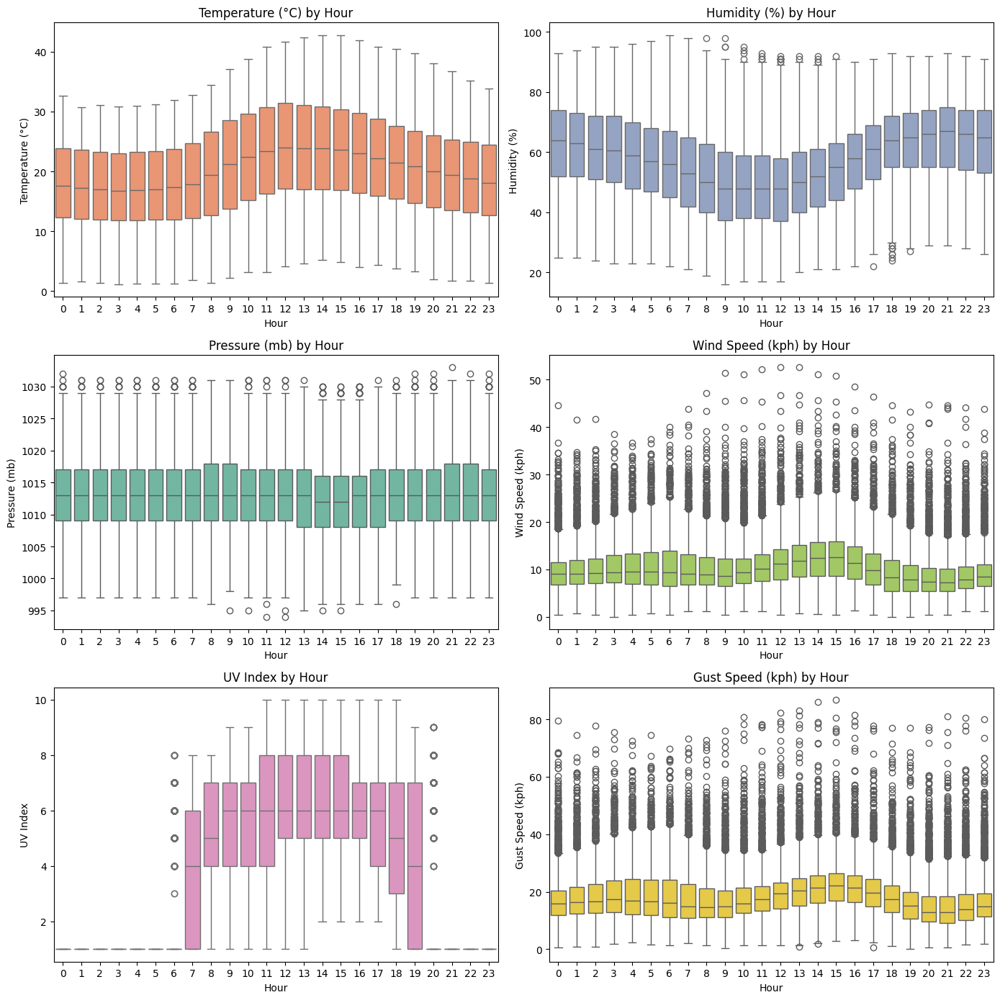

In [ ]:
variables = [
    ('temp_c', 'Temperature (°C)', '#fc8d62'),
    ('humidity', 'Humidity (%)', '#8da0cb'),
    ('pressure_mb', 'Pressure (mb)', '#66c2a5'),
    ('wind_kph', 'Wind Speed (kph)', '#a6d854'),
    ('uv', 'UV Index', '#e78ac3'),
    ('gust_kph', 'Gust Speed (kph)', '#ffd92f')
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, (col, ylabel, color) in zip(axes, variables):
    sns.boxplot(x='hour', y=col, data=df, ax=ax, color=color)
    ax.set_title(f'{ylabel} by Hour')
    ax.set_xlabel('Hour')
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()

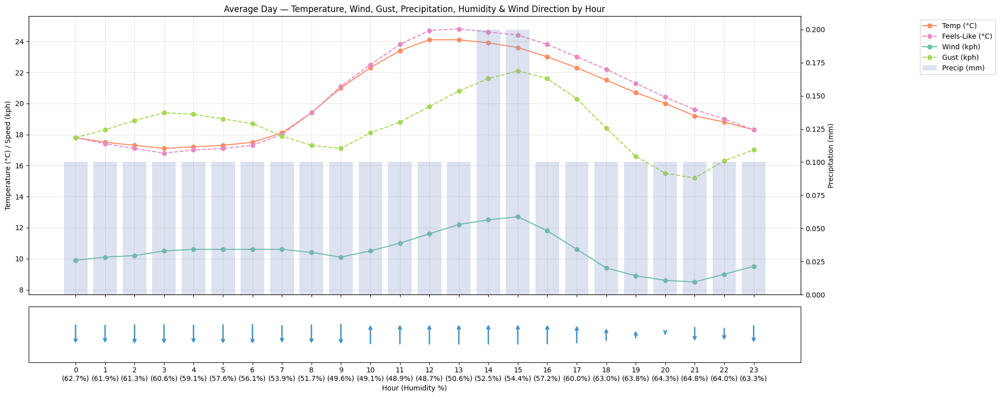

In [ ]:
def circular_mean_degrees(series):
    radians = np.deg2rad(series)
    mean_sin = np.mean(np.sin(radians))
    mean_cos = np.mean(np.cos(radians))
    return (np.rad2deg(np.arctan2(mean_sin, mean_cos))) % 360

avg_day_table = df.groupby('hour')[['temp_c', 'feelslike_c', 'precip_mm', 'wind_kph', 'gust_kph', 'humidity']].mean().round(1)
avg_day_table['wind_degree'] = df.groupby('hour')['wind_degree'].apply(circular_mean_degrees)

fig, axes = plt.subplots(2, 1, figsize=(20, 8), sharex=True,
                           gridspec_kw={'height_ratios': [4, 0.8]})

# Main combined chart
ax1 = axes[0]
ax1.plot(avg_day_table.index, avg_day_table['temp_c'], marker='o', label='Temp (°C)', color='#fc8d62')
ax1.plot(avg_day_table.index, avg_day_table['feelslike_c'], marker='o', label='Feels-Like (°C)', color='#e78ac3', linestyle='--')
ax1.plot(avg_day_table.index, avg_day_table['wind_kph'], marker='o', label='Wind (kph)', color='#66c2a5')
ax1.plot(avg_day_table.index, avg_day_table['gust_kph'], marker='o', label='Gust (kph)', color='#a6d854', linestyle='--')
ax1.set_ylabel('Temperature (°C) / Speed (kph)')
ax1.set_title('Average Day — Temperature, Wind, Gust, Precipitation, Humidity & Wind Direction by Hour')
ax1.grid(alpha=0.3)

# x-axis ticks: hour + humidity underneath, smaller font to reduce crowding
xtick_labels = [f'{h}\n({hum}%)' for h, hum in zip(avg_day_table.index, avg_day_table['humidity'])]
ax1.set_xticks(avg_day_table.index)
ax1.set_xticklabels(xtick_labels, fontsize=8)

ax2 = ax1.twinx()
ax2.bar(avg_day_table.index, avg_day_table['precip_mm'], alpha=0.3, color='#8da0cb', label='Precip (mm)')
ax2.set_ylabel('Precipitation (mm)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', bbox_to_anchor=(1.15, 1))

# Wind direction arrow row
for h, deg in zip(avg_day_table.index, avg_day_table['wind_degree']):
    dx = np.sin(np.deg2rad(deg + 180))
    dy = np.cos(np.deg2rad(deg + 180))
    axes[1].annotate('', xy=(h, dy*0.4), xytext=(h, -dy*0.4),
                       arrowprops=dict(arrowstyle='->', color='#4292c6', lw=2))
axes[1].set_ylim(-1, 1)
axes[1].set_yticks([])
axes[1].set_xlabel('Hour (Humidity %)')

plt.tight_layout()
plt.show()

**Observation:** A clear diurnal cycle, with one striking feature: average wind direction flips by roughly 180° over the course of the day — from 0–25° (N, land breeze) overnight to 180–195° (S, sea breeze) between roughly 10:00 and 17:00 — consistent with a coastal sea-breeze/land-breeze cycle, and wind speed peaks in that same midday-to-afternoon window (12.5kph at 14:00–15:00) as the sea breeze intensifies with daytime heating. Temperature bottoms out around 03:00–04:00 (17°C) and peaks at 12:00–13:00 (24°C); feels-like temperature exceeds actual temperature the most in the early afternoon (up to a 50°C max feels-like vs 43°C max actual at 13:00 in July), driven by humidity. Humidity and pressure move inversely to temperature through the day (humidity lowest 48.7% at noon; pressure shows a secondary low around 15:00 and high around 21:00 — a semidiurnal pattern common at this latitude). UV is pinned at 1 for all nighttime hours by definition, rising with daylight to a max of 10 around midday in summer months.

## Outlier Detection
Identifying outliers using the IQR method to decide whether they're
data errors or genuine extreme values worth keeping.

In [ ]:
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    return outliers, lower_bound, upper_bound

numeric_cols = ['temp_c', 'wind_kph', 'pressure_mb', 'precip_mm',
                 'humidity', 'cloud', 'dewpoint_c', 'vis_km', 'gust_kph', 'uv']

outlier_summary = {}

for col in numeric_cols:
    outliers, lower, upper = detect_outliers_iqr(df, col)
    outlier_summary[col] = {
        'count': len(outliers),
        'percent': round(len(outliers) / len(df) * 100, 2),
        'lower_bound': round(lower, 2),
        'upper_bound': round(upper, 2)
    }

outlier_summary_df = pd.DataFrame(outlier_summary).T
outlier_summary_df

,count,percent,lower_bound,upper_bound
temp_c,0.0,0.00,-4.55,44.65
wind_kph,1962.0,3.26,-2.90,22.70
pressure_mb,147.0,0.24,997.00,1029.00
precip_mm,6420.0,10.66,0.00,0.00
humidity,0.0,0.00,11.50,103.50
cloud,7811.0,12.97,-40.00,72.00
dewpoint_c,328.0,0.54,-5.15,28.85
vis_km,7374.0,12.24,10.00,10.00
gust_kph,2129.0,3.53,-4.25,39.35
uv,0.0,0.00,-6.50,13.50


**Observation:** IQR-based outlier detection worked cleanly for temp_c, humidity,

* uv, dewpoint_c, and pressure_mb (0-0.5% outliers, as expected for well-behaved
distributions).

* However, precip_mm, vis_km, and cloud show inflated outlier
percentages (11-13%) due to their skewed or capped distributions rather than
genuine data errors — precip_mm and vis_km in particular have zero IQR range
since their 25th-75th percentiles collapse to a single repeated value (0 and
10km respectively).

* wind_kph (3.3%) and gust_kph (3.5%) show the most
meaningful outliers — likely genuine strong-wind events worth investigating
further rather than removing.

In [ ]:
wind_outliers, _, _ = detect_outliers_iqr(df, 'wind_kph')
wind_outliers[['time','temp_c','wind_dir' ,'wind_kph', 'gust_kph', 'condition']].sort_values('wind_kph', ascending=False).head(10)

,time,temp_c,wind_dir,wind_kph,gust_kph,condition
54660,2023-03-29 12:00:00,14.9,NW,52.6,60.5,Sunny
54661,2023-03-29 13:00:00,15.1,NW,52.6,60.5,Sunny
54659,2023-03-29 11:00:00,14.6,NW,52.2,60.1,Sunny
54657,2023-03-29 09:00:00,12.6,NW,51.5,59.0,Sunny
54658,2023-03-29 10:00:00,13.4,NW,51.1,58.7,Sunny
54662,2023-03-29 14:00:00,15.4,NW,51.1,58.7,Sunny
54663,2023-03-29 15:00:00,15.7,NW,50.8,58.3,Sunny
54664,2023-03-29 16:00:00,15.8,NW,48.6,55.8,Sunny
54656,2023-03-29 08:00:00,12.0,NW,47.2,56.5,Patchy rain possible
35676,2021-01-27 12:00:00,14.4,S,46.8,82.4,Moderate or heavy rain shower


In [ ]:
wind_outliers, _, _ = detect_outliers_iqr(df, 'wind_kph')
wind_outliers['date'] = wind_outliers['time'].dt.date

daily_outlier_summary = wind_outliers.groupby('date').agg(
    outlier_hours=('wind_kph', 'count'),
    avg_temp=('temp_c', 'mean'),
    avg_humidity=('humidity', 'mean'),
    avg_wind_kph=('wind_kph', 'mean'),
    max_wind_kph=('wind_kph', 'max'),
    max_gust_kph=('gust_kph', 'max'),
    dominant_wind_dir=('wind_dir', lambda x: x.mode()[0]),
    dominant_condition=('condition', lambda x: x.mode()[0])
).sort_values('outlier_hours', ascending=False)

daily_outlier_summary.head(10)

/tmp/ipykernel_2030/3210783013.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wind_outliers['date'] = wind_outliers['time'].dt.date


,outlier_hours,avg_temp,avg_humidity,avg_wind_kph,max_wind_kph,max_gust_kph,dominant_wind_dir,dominant_condition
date,,,,,,,,
2020-03-17,24,9.045833,55.791667,28.683333,34.9,52.1,NNW,Partly cloudy
2020-01-21,24,8.925000,52.583333,27.295833,30.4,51.1,NNW,Clear
2020-02-08,24,5.983333,52.416667,29.212500,33.6,52.2,NNW,Clear
2021-02-17,24,4.737500,49.125000,29.470833,32.5,54.6,NNW,Sunny
2021-04-10,24,11.570833,47.041667,32.083333,36.3,60.1,NNW,Partly cloudy
2021-01-27,23,13.830435,73.565217,37.900000,46.8,82.4,SSE,Moderate or heavy rain shower
2019-12-23,23,15.169565,79.608696,32.891304,40.3,81.2,SSW,Moderate or heavy rain shower
2018-12-27,23,7.569565,48.782609,25.700000,28.1,53.0,N,Clear
2021-12-07,23,16.669565,77.608696,33.291304,43.4,77.9,SSE,Moderate or heavy rain shower


**Observation:** The wind-speed outliers split into two distinct regimes by direction. Most of the extreme days (7 of 10, e.g. 2020-03-17, 2021-02-17, 2021-04-10) are dominated by N/NNW wind, paired with cold temperatures (5–17°C) and moderate humidity (47–56%) — a dry, cold-air-mass signature. A smaller subset (2021-01-27, 2019-12-23, 2021-12-07) is dominated by S/SSE/SSW wind, paired with much higher humidity (74–80%) and rain-bearing conditions ('Moderate or heavy rain shower'). This split holds more broadly across the dataset: humidity rises with wind speed for southerly wind but falls with wind speed for northerly wind (see the wind-direction analysis further down), so strong wind on its own isn't a reliable signal of 'humid' weather here — direction is what determines whether it's a dry cold snap or a wet front, consistent with Antalya sitting in a frontal transition zone between cold continental air (N) and moist Mediterranean/African air (S).

## Relationship Exploration  

In [ ]:
def simplify_wind_dir(direction):
    n_dirs = ['N', 'NNE', 'NNW', 'NE', 'NW']
    e_dirs = ['E', 'ENE', 'ESE']
    s_dirs = ['S', 'SSE', 'SSW', 'SE', 'SW']
    w_dirs = ['W', 'WNW', 'WSW']

    if direction in n_dirs:
        return 'N'
    elif direction in e_dirs:
        return 'E'
    elif direction in s_dirs:
        return 'S'
    elif direction in w_dirs:
        return 'W'
    else:
        return 'Other'

df['wind_dir_group'] = df['wind_dir'].apply(simplify_wind_dir)
df['wind_dir_group'].value_counts()

,count
wind_dir_group,
N,24030
S,21306
E,9817
W,5087


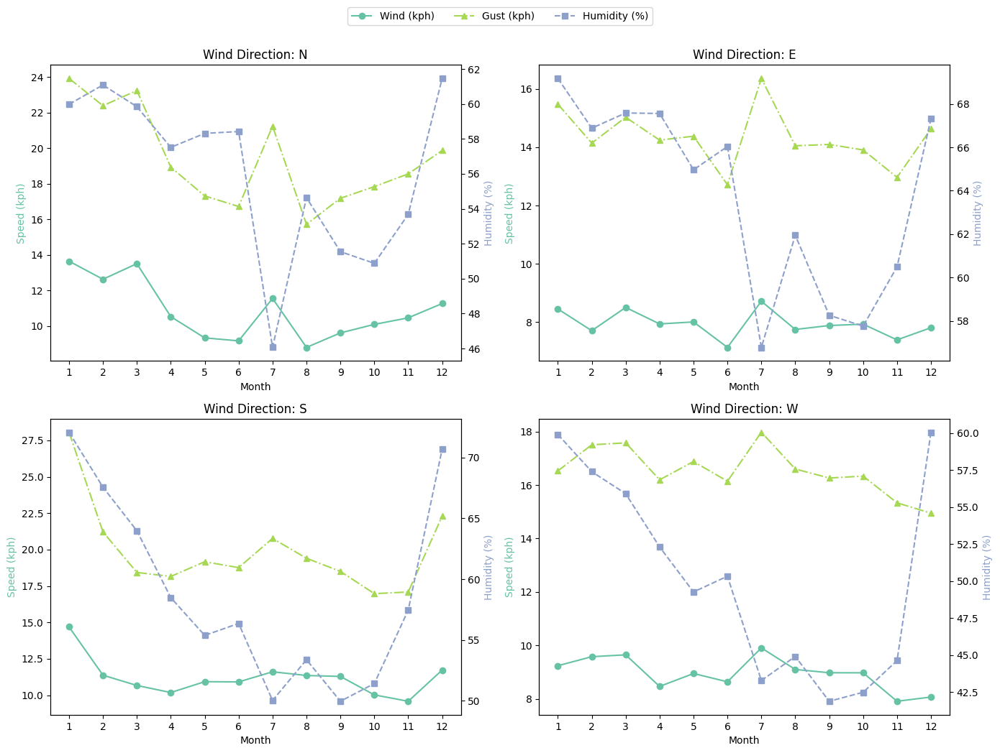

In [ ]:
def simplify_wind_dir(direction):
    n_dirs = ['N', 'NNE', 'NNW', 'NE', 'NW']
    e_dirs = ['E', 'ENE', 'ESE']
    s_dirs = ['S', 'SSE', 'SSW', 'SE', 'SW']
    w_dirs = ['W', 'WNW', 'WSW']

    if direction in n_dirs:
        return 'N'
    elif direction in e_dirs:
        return 'E'
    elif direction in s_dirs:
        return 'S'
    elif direction in w_dirs:
        return 'W'
    else:
        return 'Other'

df['wind_dir_group'] = df['wind_dir'].apply(simplify_wind_dir)
directions = ['N', 'E', 'S', 'W']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, direction in zip(axes, directions):
    subset = df[df['wind_dir_group'] == direction]
    monthly_avg = subset.groupby('month')[['wind_kph', 'gust_kph', 'humidity']].mean()

    ax2 = ax.twinx()
    l1, = ax.plot(monthly_avg.index, monthly_avg['wind_kph'], marker='o', color='#66c2a5', label='Wind (kph)')
    l2, = ax.plot(monthly_avg.index, monthly_avg['gust_kph'], marker='^', color='#a6d854', linestyle='-.', label='Gust (kph)')
    l3, = ax2.plot(monthly_avg.index, monthly_avg['humidity'], marker='s', color='#8da0cb', linestyle='--', label='Humidity (%)')

    ax.set_title(f'Wind Direction: {direction}')
    ax.set_xlabel('Month')
    ax.set_ylabel('Speed (kph)', color='#66c2a5')
    ax2.set_ylabel('Humidity (%)', color='#8da0cb')
    ax.set_xticks(range(1, 13))

# Single shared legend for the whole figure
fig.legend([l1, l2, l3], ['Wind (kph)', 'Gust (kph)', 'Humidity (%)'],
           loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3, fontsize=10)

plt.tight_layout()
plt.show()

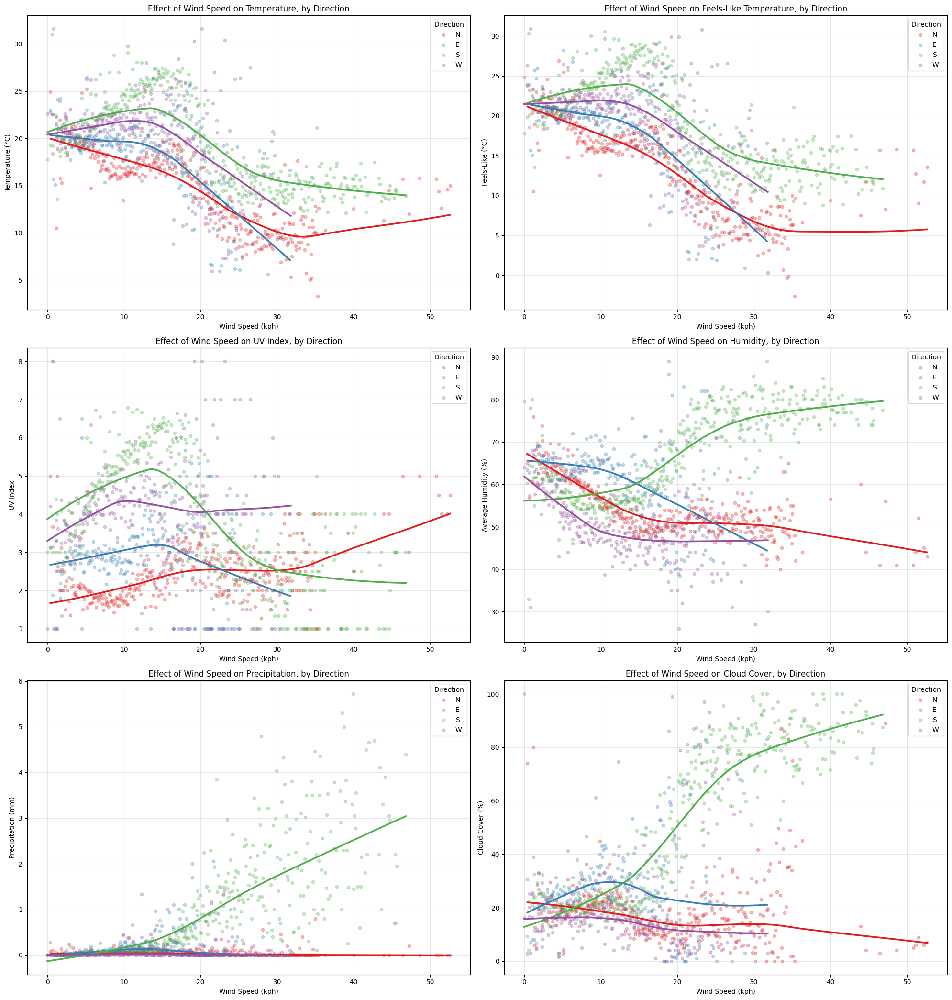

In [ ]:
wind_humidity_dir = df.groupby(['wind_kph', 'wind_dir_group'])['humidity'].mean().reset_index()
wind_temp_dir = df.groupby(['wind_kph', 'wind_dir_group'])['temp_c'].mean().reset_index()
wind_precip_dir = df.groupby(['wind_kph', 'wind_dir_group'])['precip_mm'].mean().reset_index()
wind_feelslike_dir = df.groupby(['wind_kph', 'wind_dir_group'])['feelslike_c'].mean().reset_index()
wind_uv_dir = df.groupby(['wind_kph', 'wind_dir_group'])['uv'].mean().reset_index()
wind_cloud_dir = df.groupby(['wind_kph', 'wind_dir_group'])['cloud'].mean().reset_index()

fig, axes = plt.subplots(3, 2, figsize=(20, 21))

directions_colors = list(zip(['N', 'E', 'S', 'W'], ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']))

def plot_wind_effect(ax, data, y_col, title, ylabel):
    for direction, color in directions_colors:
        subset = data[data['wind_dir_group'] == direction]
        sns.regplot(x='wind_kph', y=y_col, data=subset,
                    scatter_kws={'alpha': 0.3, 's': 20, 'color': color},
                    line_kws={'color': color, 'linewidth': 2.5},
                    label=direction, lowess=True, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Wind Speed (kph)')
    ax.set_ylabel(ylabel)
    ax.legend(title='Direction')
    ax.grid(alpha=0.3)

plot_wind_effect(axes[0, 0], wind_temp_dir, 'temp_c',
                  'Effect of Wind Speed on Temperature, by Direction', 'Temperature (°C)')

plot_wind_effect(axes[0, 1], wind_feelslike_dir, 'feelslike_c',
                  'Effect of Wind Speed on Feels-Like Temperature, by Direction', 'Feels-Like (°C)')

plot_wind_effect(axes[1, 0], wind_uv_dir, 'uv',
                  'Effect of Wind Speed on UV Index, by Direction', 'UV Index')

plot_wind_effect(axes[1, 1], wind_humidity_dir, 'humidity',
                  'Effect of Wind Speed on Humidity, by Direction', 'Average Humidity (%)')

plot_wind_effect(axes[2, 0], wind_precip_dir, 'precip_mm',
                  'Effect of Wind Speed on Precipitation, by Direction', 'Precipitation (mm)')

plot_wind_effect(axes[2, 1], wind_cloud_dir, 'cloud',
                  'Effect of Wind Speed on Cloud Cover, by Direction', 'Cloud Cover (%)')

plt.tight_layout()
plt.show()

**Observation:** The six panels split cleanly into two regimes by direction. Southerly (S) wind is the "wet" regime: as S wind speed increases, humidity rises (56%→80%), cloud cover rises sharply (20%→90%), and precipitation, flat at 0 for every other direction, climbs to 2–6mm at the highest S wind speeds. S also stays the warmest direction at every wind speed (temperature and feels-like both decline the least, ending 14–17°C vs 5–12°C for the others) and shows the highest UV at low-to-moderate speed (peaking 5.2 around 10–15kph), consistent with warmer, more humid but not yet fully overcast southerly flow. N/E/W wind is the "dry" regime: humidity and cloud cover stay flat or fall as wind strengthens, precipitation stays pinned near zero regardless of speed, and temperature/feels-like drop the furthest (N feels-like falls below 5°C at high wind — a wind-chill signature). N in particular has the lowest UV of all four directions at low wind speed, rising only at the highest speeds where sample size thins out. Together this confirms the earlier finding: wind strength alone doesn't indicate "stormy" weather here — only southerly wind carries the humidity, cloud, and rain signal, while northerly/easterly/westerly wind of the same speed is a dry, cold-air event.


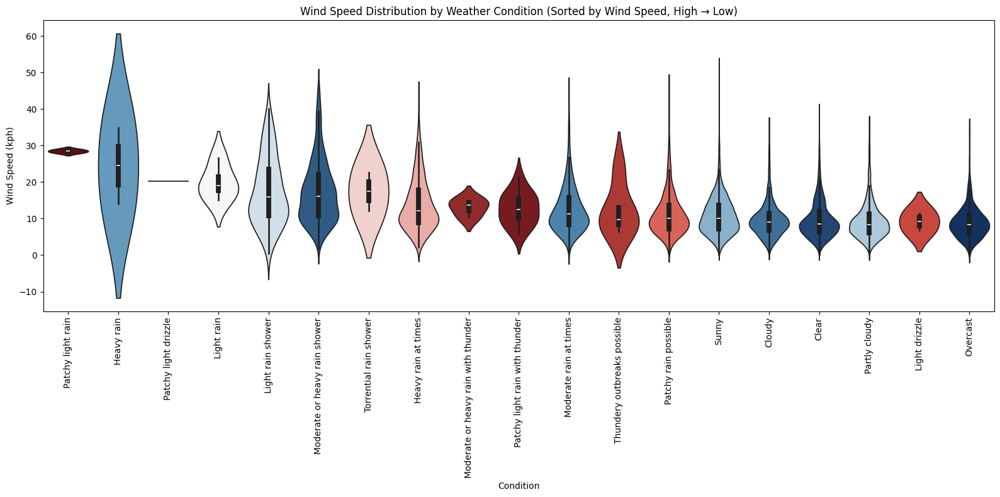

In [ ]:
import matplotlib.colors as mcolors

manual_order = [
    'Heavy rain',
    'Moderate or heavy rain shower',
    'Moderate or heavy rain with thunder',
    'Torrential rain shower',
    'Heavy rain at times',
    'Moderate rain at times',
    'Light rain shower',
    'Light rain',
    'Patchy light rain with thunder',
    'Thundery outbreaks possible',
    'Patchy rain possible',
    'Patchy light rain',
    'Light drizzle',
    'Patchy light drizzle',
    'Overcast',
    'Cloudy',
    'Partly cloudy',
    'Clear',
    'Sunny'
]

existing_conditions = df['condition'].unique()
manual_order_filtered = [c for c in manual_order if c in existing_conditions]


cmap = mcolors.LinearSegmentedColormap.from_list('blue_red', ['#08306b', '#4292c6', '#f7f7f7', '#ef3b2c', '#67000d'])
n_conditions = len(manual_order_filtered)
condition_color_map = {cond: cmap(i / (n_conditions - 1)) for i, cond in enumerate(manual_order_filtered)}

order_by_wind = df.groupby('condition')['wind_kph'].mean().sort_values(ascending=False).index

bar_colors = [condition_color_map[cond] for cond in order_by_wind]

plt.figure(figsize=(16, 8))
sns.violinplot(x='condition', y='wind_kph', data=df, order=order_by_wind,
               hue='condition', palette=bar_colors, legend=False)
plt.title('Wind Speed Distribution by Weather Condition (Sorted by Wind Speed, High → Low)')
plt.xlabel('Condition')
plt.ylabel('Wind Speed (kph)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

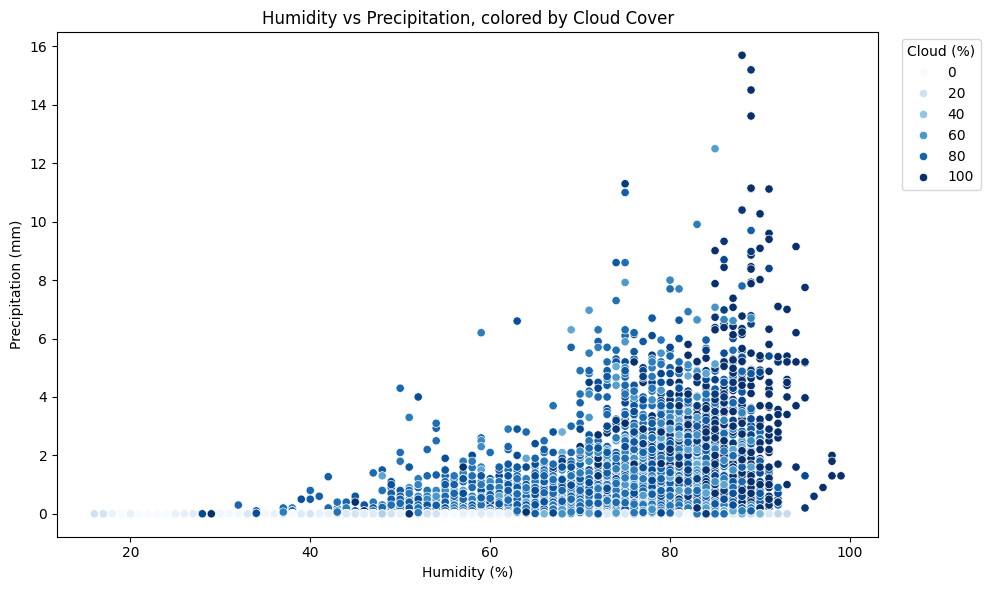

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='humidity', y='precip_mm', hue='cloud', palette='Blues', data=df)
plt.title('Humidity vs Precipitation, colored by Cloud Cover')
plt.xlabel('Humidity (%)')
plt.ylabel('Precipitation (mm)')
plt.legend(title='Cloud (%)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

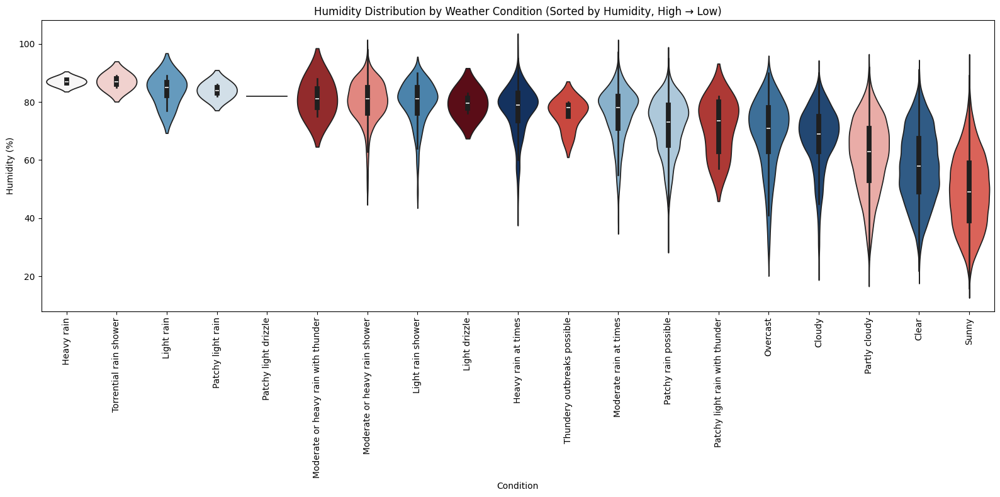

In [ ]:
import matplotlib.colors as mcolors


cmap = mcolors.LinearSegmentedColormap.from_list('blue_red', ['#08306b', '#4292c6', '#f7f7f7', '#ef3b2c', '#67000d'])
n_conditions = len(manual_order_filtered)
condition_color_map = {cond: cmap(i / (n_conditions - 1)) for i, cond in enumerate(manual_order_filtered)}


order_by_humidity = df.groupby('condition')['humidity'].mean().sort_values(ascending=False).index

bar_colors = [condition_color_map[cond] for cond in order_by_humidity]

plt.figure(figsize=(16, 8))
sns.violinplot(x='condition', y='humidity', data=df, order=order_by_humidity,
               hue='condition', palette=bar_colors, legend=False)
plt.title('Humidity Distribution by Weather Condition (Sorted by Humidity, High → Low)')
plt.xlabel('Condition')
plt.ylabel('Humidity (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

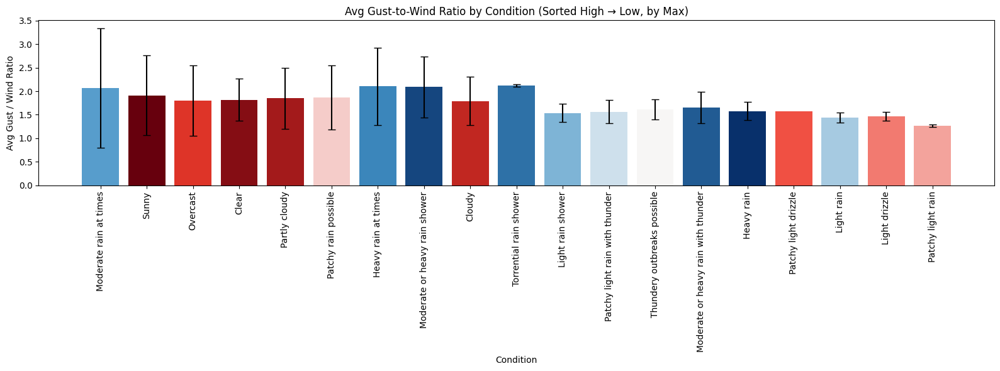

In [ ]:
import numpy as np
import matplotlib.colors as mcolors


df['gust_wind_ratio'] = df['gust_kph'] / df['wind_kph'].replace(0, np.nan)

cmap = mcolors.LinearSegmentedColormap.from_list('blue_red', ['#08306b', '#4292c6', '#f7f7f7', '#ef3b2c', '#67000d'])
n_conditions = len(manual_order_filtered)
condition_color_map = {cond: cmap(i / (n_conditions - 1)) for i, cond in enumerate(manual_order_filtered)}

order_by_max = df.groupby('condition')['gust_wind_ratio'].max().sort_values(ascending=False).index
summary_sorted = df.groupby('condition')['gust_wind_ratio'].agg(['mean', 'std']).reindex(order_by_max)

bar_colors = [condition_color_map[cond] for cond in summary_sorted.index]

plt.figure(figsize=(16, 6))
plt.bar(summary_sorted.index, summary_sorted['mean'], yerr=summary_sorted['std'], capsize=4, color=bar_colors)
plt.title('Avg Gust-to-Wind Ratio by Condition (Sorted High → Low, by Max)')
plt.xlabel('Condition')
plt.ylabel('Avg Gust / Wind Ratio')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Observation:** Weather `condition` labels track both wind speed and humidity in a mostly consistent, monotonic way: rain-related conditions have the highest median wind speed (`Heavy rain` ~25kph) and the highest median humidity (85–90%), while `Sunny`/`Clear`/`Overcast` sit at the low end for both (8–10kph, 49–59% humidity) — a useful sanity check that the condition text is internally consistent with the numeric fields. Two exceptions stand out: (1) `Sunny` has an unusually wide wind-speed spread, reaching the same ~54kph extreme seen in the wind outlier analysis (the Föhn-like NW wind events); (2) the gust-to-wind ratio does *not* follow the same ordering — it's fairly flat (1.3–2.1) across all conditions, so gustiness/turbulence looks more like a general wind-mechanics property than something tied to precipitation intensity. Separately, heavy precipitation (>8mm) only occurs at both high humidity (>85%) and high cloud cover simultaneously — neither variable alone is sufficient.

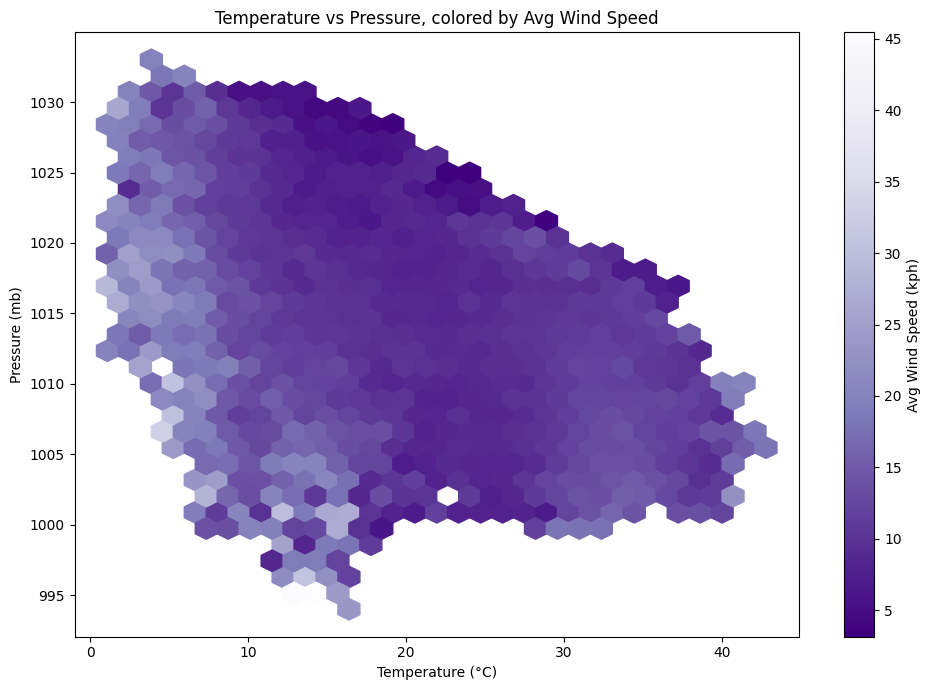

In [ ]:
plt.figure(figsize=(10, 7))
plt.hexbin(df['temp_c'], df['pressure_mb'], C=df['wind_kph'], gridsize=30, cmap='Purples_r', reduce_C_function=np.mean)
plt.colorbar(label='Avg Wind Speed (kph)')
plt.title('Temperature vs Pressure, colored by Avg Wind Speed')
plt.xlabel('Temperature (°C)')
plt.ylabel('Pressure (mb)')
plt.tight_layout()
plt.show()

**Observation:** Wind speed isn't driven by temperature directly — the darkest (calmest, <15kph) hexbins fill almost the entire temperature range. Instead, the strongest average wind speeds cluster at the *extremes* of the pressure axis — both the lowest pressures (995–1005mb, active low-pressure systems) and the highest (1028–1033mb, in cooler conditions) — while the mid-range pressure band (1010–1020mb) is calmest regardless of temperature.

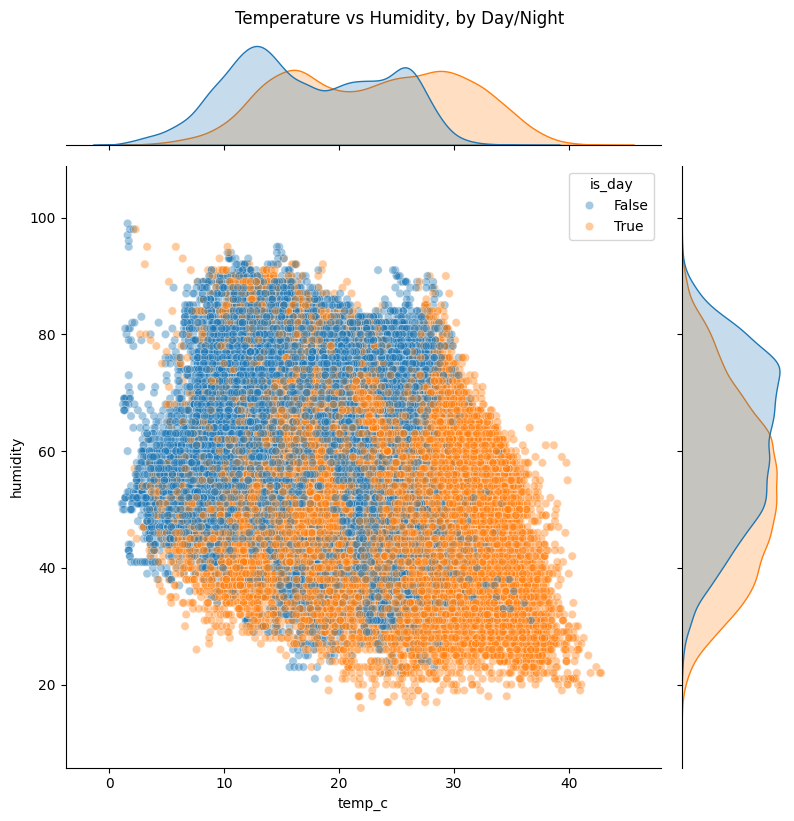

In [ ]:
g = sns.jointplot(data=df, x='temp_c', y='humidity', hue='is_day', alpha=0.4, height=8)
g.fig.suptitle('Temperature vs Humidity, by Day/Night', y=1.02)
plt.show()

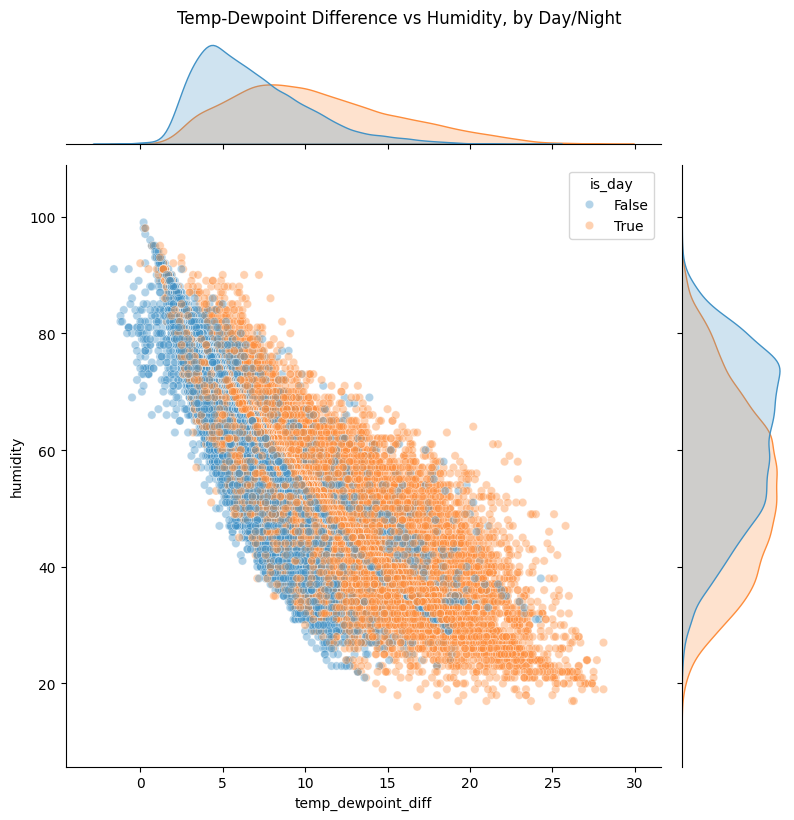

In [ ]:
df['temp_dewpoint_diff'] = df['temp_c'] - df['dewpoint_c']
g = sns.jointplot(data=df, x='temp_dewpoint_diff', y='humidity', hue='is_day',
                   palette={True: '#fd8d3c', False: '#4292c6'}, alpha=0.4, height=8)
g.fig.suptitle('Temp-Dewpoint Difference vs Humidity, by Day/Night', y=1.02)
plt.show()

**Observation:** Both plots confirm the expected diurnal pattern rather than surfacing a new one: nighttime hours (blue) skew toward lower temperatures and higher humidity (marginal peak 75–80%), while daytime hours (orange) skew toward higher temperatures and lower humidity (marginal peak 50–60%), though the two overlap heavily and both span nearly the full range. The temp-dewpoint-difference vs humidity relationship is tight and near-deterministic by construction (dewpoint depression directly determines relative humidity), with nighttime sitting closer to saturation (peak diff 4–5°C) than daytime (7–8°C) — consistent with nighttime cooling raising relative humidity.

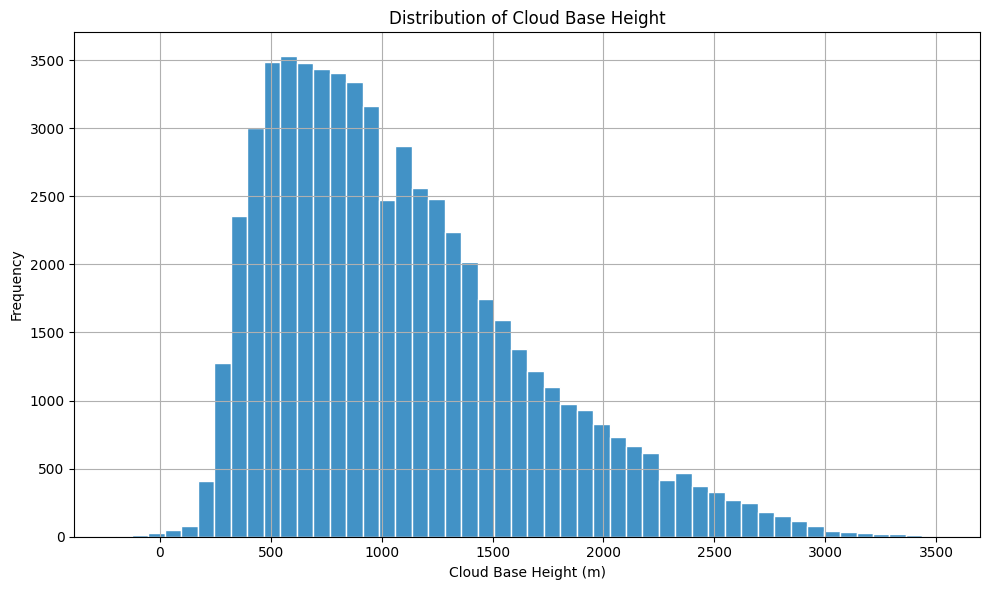

In [ ]:
df['cloud_base_m'] = df['temp_dewpoint_diff'] * 125
plt.figure(figsize=(10, 6))
df['cloud_base_m'].hist(bins=50, color='#4292c6', edgecolor='white')
plt.title('Distribution of Cloud Base Height')
plt.xlabel('Cloud Base Height (m)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

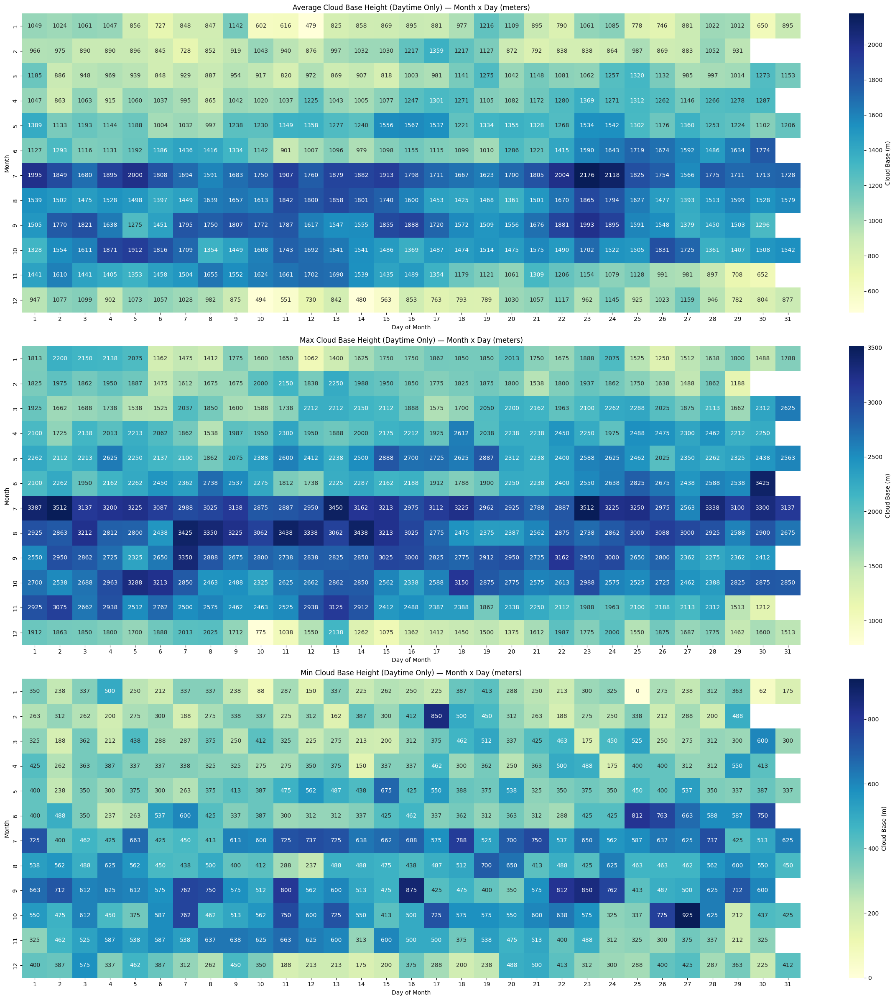

In [ ]:
df['day'] = df['time'].dt.day

day_only = df[df['is_day'] == True]

cloud_base_mean = day_only.groupby(['month', 'day'])['cloud_base_m'].mean().unstack()
cloud_base_max = day_only.groupby(['month', 'day'])['cloud_base_m'].max().unstack()
cloud_base_min = day_only.groupby(['month', 'day'])['cloud_base_m'].min().unstack()

fig, axes = plt.subplots(3, 1, figsize=(24, 24))

sns.heatmap(cloud_base_mean, cmap='YlGnBu', annot=True, fmt='.0f',
            cbar_kws={'label': 'Cloud Base (m)'}, ax=axes[0])
axes[0].set_title('Average Cloud Base Height (Daytime Only) — Month x Day (meters)')
axes[0].set_xlabel('Day of Month')
axes[0].set_ylabel('Month')

sns.heatmap(cloud_base_max, cmap='YlGnBu', annot=True, fmt='.0f',
            cbar_kws={'label': 'Cloud Base (m)'}, ax=axes[1])
axes[1].set_title('Max Cloud Base Height (Daytime Only) — Month x Day (meters)')
axes[1].set_xlabel('Day of Month')
axes[1].set_ylabel('Month')

sns.heatmap(cloud_base_min, cmap='YlGnBu', annot=True, fmt='.0f',
            cbar_kws={'label': 'Cloud Base (m)'}, ax=axes[2])
axes[2].set_title('Min Cloud Base Height (Daytime Only) — Month x Day (meters)')
axes[2].set_xlabel('Day of Month')
axes[2].set_ylabel('Month')

plt.tight_layout()
plt.show()

**Observation:** Cloud base height shows a clear seasonal pattern, with
July-August (months 7-8) showing the highest average base heights
(1,500-2,000m, peaking near 2,176m around July 23-24) — consistent with
hot, dry summer air holding moisture farther from saturation. Winter months
(December-January) show the lowest averages (500-1,150m), and the min-panel
confirms this: several winter days drop to extremely low cloud bases
(0-250m), indicating near-surface saturation and fog risk on those specific
mornings. The max panel shows summer days occasionally reaching very high
bases (3,000-3,500m) during the driest afternoon hours, while winter maxes
rarely exceed 2,000-2,600m.

**Note:** This analysis is restricted to daytime hours (`is_day == True`)
deliberately. Nighttime radiative cooling causes strong near-surface
temperature inversions, where the ground cools faster than the air above it —
this artificially shrinks the temp-dewpoint gap overnight regardless of the
actual moisture content of the air mass, producing misleadingly low cloud
base estimates that don't reflect genuine cloud formation. Restricting to
daytime avoids this inversion artifact and gives a more physically meaningful
picture of cloud base behavior.

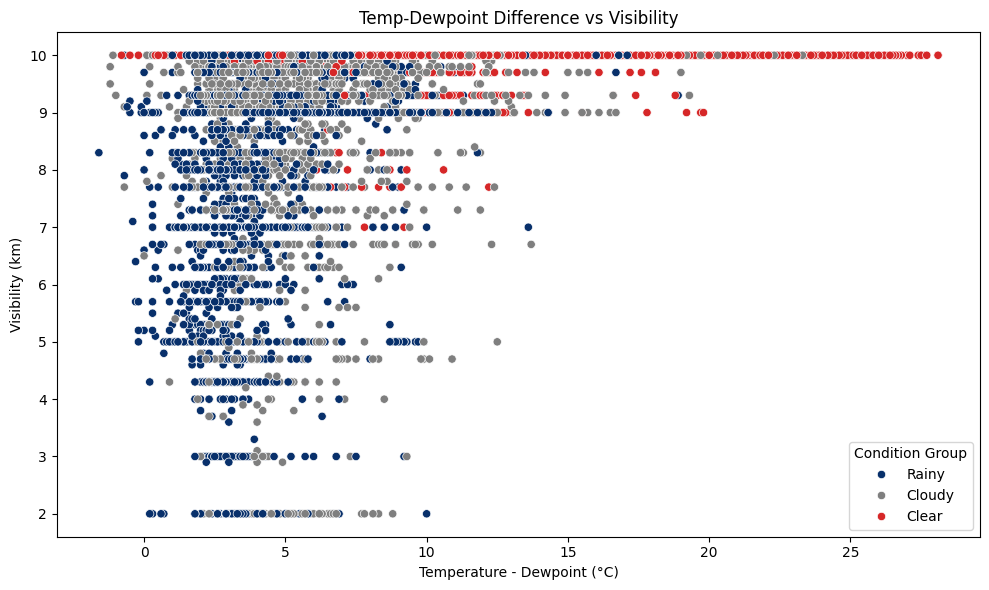

In [ ]:
color_map = {
    'Clear': '#d62728',
    'Cloudy': '#7f7f7f',
    'Rainy': '#08306b',
    'Other': '#999999'
}
plt.figure(figsize=(10, 6))
sns.scatterplot(x='temp_dewpoint_diff', y='vis_km',hue='condition_group',palette=color_map, data=df)
plt.title('Temp-Dewpoint Difference vs Visibility')
plt.xlabel('Temperature - Dewpoint (°C)')
plt.ylabel('Visibility (km)')
plt.legend(title='Condition Group', loc='lower right')
plt.tight_layout()
plt.show()

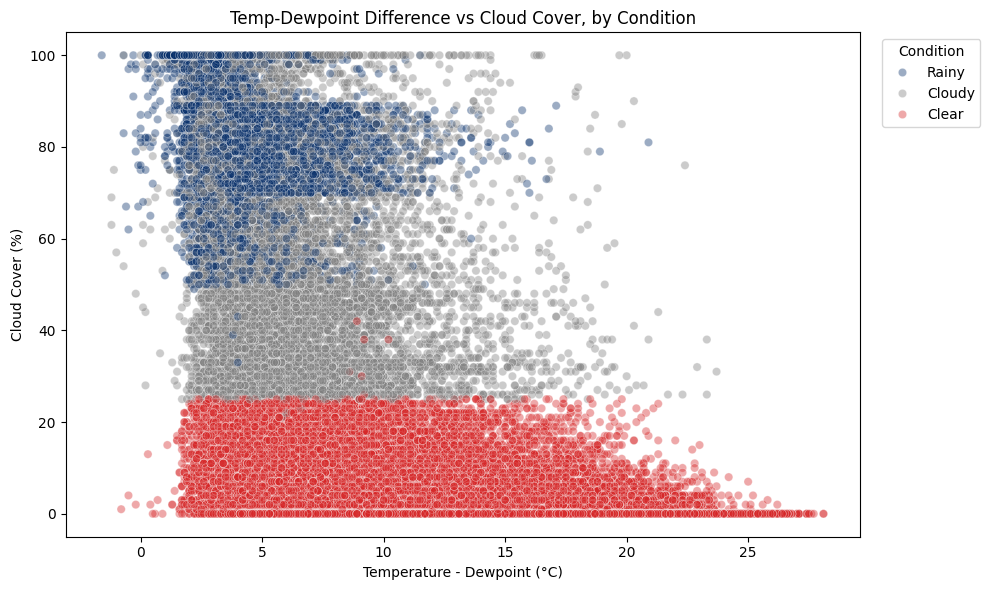

In [ ]:


plt.figure(figsize=(10, 6))
sns.scatterplot(x='temp_dewpoint_diff', y='cloud', hue='condition_group', palette=color_map, data=df, alpha=0.4)
plt.title('Temp-Dewpoint Difference vs Cloud Cover, by Condition')
plt.xlabel('Temperature - Dewpoint (°C)')
plt.ylabel('Cloud Cover (%)')
plt.legend(title='Condition', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Observation:** Reduced visibility (<7km) is almost entirely a `Rainy`/`Cloudy` phenomenon that also requires near-saturated air (temp-dewpoint difference near 0°C) — `Clear` hours stay pinned at 9–10km visibility across the *entire* temp-dewpoint-difference range. The cloud-cover plot shows the same three-way stratification even more cleanly: `Clear` occupies cloud cover <30%, `Cloudy` the 30–100% band, and `Rainy` concentrates in high cloud cover (>50%) *and* low temp-dewpoint difference (0–10°C) — rain needs both a cloudy sky and air close to its dew point.

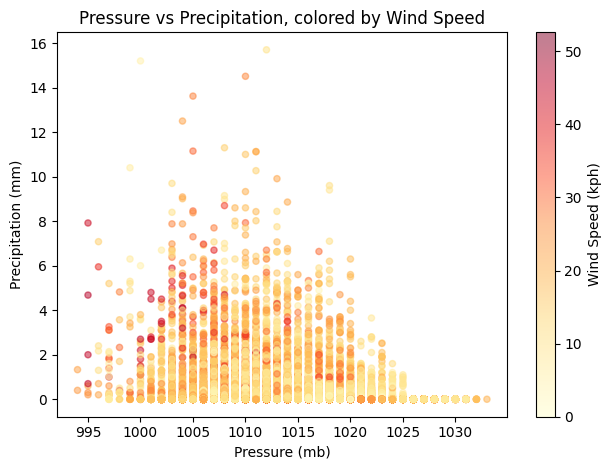

In [ ]:
scatter = plt.scatter(df['pressure_mb'], df['precip_mm'], c=df['wind_kph'], cmap='YlOrRd', alpha=0.5, s=20)
plt.colorbar(scatter, label='Wind Speed (kph)')
plt.title('Pressure vs Precipitation, colored by Wind Speed')
plt.xlabel('Pressure (mb)')
plt.ylabel('Precipitation (mm)')
plt.tight_layout()
plt.show()

**Observation:** Precipitation is confined to pressure below ~1025mb, and the heaviest rain (>10mm) clusters specifically in the 1000–1013mb range. Rain events also tend to run windier (more orange/red points) than dry hours at the same pressure, and high pressure (>1025mb) is both dry and calm — reinforcing that low-to-mid pressure is where both wind and rain originate together (active weather systems), while high pressure brings settled, calm conditions.

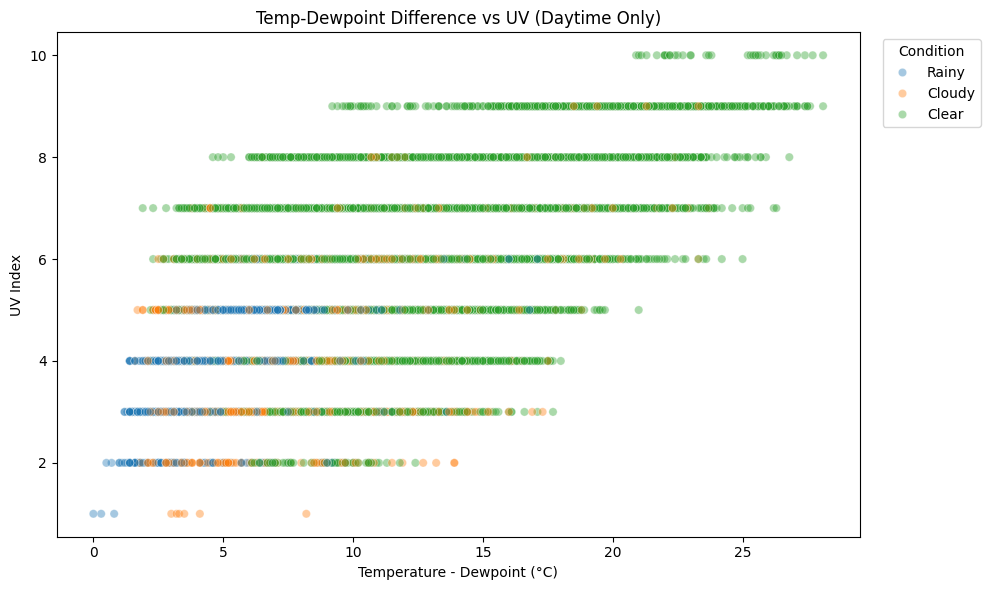

In [ ]:
day_only = df[df['is_day'] == True]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='temp_dewpoint_diff', y='uv', hue='condition_group', data=day_only, alpha=0.4)
plt.title('Temp-Dewpoint Difference vs UV (Daytime Only)')
plt.xlabel('Temperature - Dewpoint (°C)')
plt.ylabel('UV Index')
plt.legend(title='Condition', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Observation:** High UV (8–10) is exclusively a `Clear`-sky phenomenon, occurring across a wide range of temp-dewpoint difference. Low UV (1–3) during daytime hours is shared across all three condition groups but concentrates at low temp-dewpoint difference (near-saturated, humid air) — consistent with the cloud-vs-UV relationship seen earlier, where cloud cover (which correlates with low temp-dewpoint difference) suppresses UV regardless of condition label.

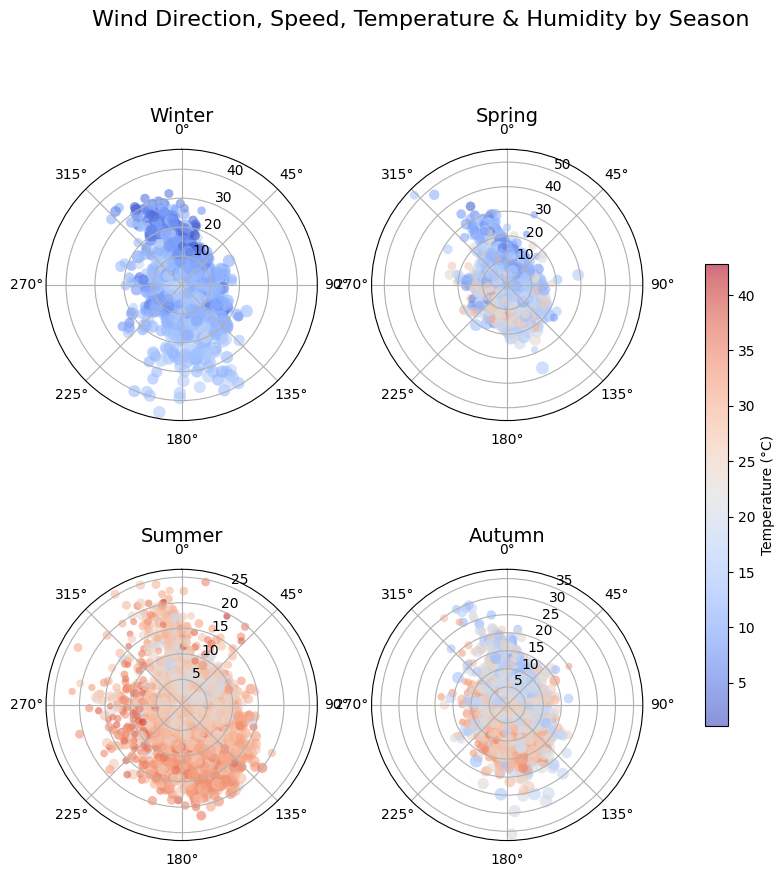

In [ ]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season)

seasons = ['Winter', 'Spring', 'Summer', 'Autumn']

fig, axes = plt.subplots(2, 2, figsize=(10, 10), subplot_kw={'projection': 'polar'})
axes = axes.flatten()

vmin, vmax = df['temp_c'].min(), df['temp_c'].max()

for ax, season in zip(axes, seasons):
    subset = df[df['season'] == season].sample(min(2000, len(df[df['season'] == season])), random_state=42)

    angles_rad = np.deg2rad(subset['wind_degree'])
    radii = subset['wind_kph']
    colors = subset['temp_c']
    sizes = subset['humidity']

    sc = ax.scatter(angles_rad, radii, c=colors, s=sizes, cmap='coolwarm',
                     alpha=0.6, edgecolors='none', vmin=vmin, vmax=vmax)

    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_title(f'{season}', pad=20, fontsize=14)


cbar = fig.colorbar(sc, ax=axes, pad=0.08, shrink=0.6)
cbar.set_label('Temperature (°C)')

fig.suptitle('Wind Direction, Speed, Temperature & Humidity by Season', fontsize=16, y=0.98)
plt.show()

**Observation:** This ties together the seasonal and directional threads from earlier: winter and spring wind is bimodal (clustered around both ~0–45° N/NNE and ~180–225° S/SSW) and reaches the highest speeds (>40kph, matching the wind outlier events found earlier), with cool colors dominating. Summer wind is calmer (rarely exceeding ~25kph) and much more tightly clustered around the southerly 180–225° sector, with warm colors dominating — the seasonal signature of a coastal Mediterranean climate where summer flow is more uniformly onshore (south) while winter brings a wider mix of cold northerly outbreaks and warm southerly fronts.

## SUMMARY

**Dataset:** 60,240 hourly weather observations for Serik, Antalya (Feb 2017 – Nov 2023), 32 columns, no missing values, no duplicates. Four columns (`will_it_rain`, `will_it_snow`, `chance_of_rain`, `chance_of_snow`) were constant zeros and dropped; unit-duplicate columns (°C/°F, mph/kph, mb/in) correlate at ~0.99–1.00 as expected.

**Overall climate:** A textbook Mediterranean profile — hot dry summers (Jul/Aug mean ~30°C, humidity ~49%, near-zero rain Jun–Sep every single year) and mild wet winters (Jan mean ~11°C, humidity ~65%, most of the year's rain falling Nov–Mar). `Sunny`/`Clear` account for ~79% of all hours. The seasonal shape is highly consistent across all 7 years, though 2020 had noticeably more cloud cover and January 2019 saw one extreme rain month (693mm vs a typical <300mm/month).

**Diurnal cycle — the most notable finding:** average wind direction flips ~180° over the course of a day — northerly (land breeze) overnight, southerly (sea breeze) from roughly 10:00–17:00 — a classic coastal sea-breeze/land-breeze cycle, with wind speed peaking in that same afternoon window.

**Wind direction drives moisture, temperature, and rain — not just speed:** a six-panel breakdown of temperature, feels-like, UV, humidity, precipitation, and cloud cover against wind speed, split by direction, shows two clean regimes. Southerly (S) wind is the "wet" regime — as it strengthens, humidity rises (56%→ 80%), cloud cover rises sharply (20%→ 90%), and precipitation (flat at 0 for every other direction) climbs to 2–6mm; S also stays the warmest direction at every wind speed and shows the highest UV at low-to-moderate speed (peaking 5.2 around 10–15kph). N/E/W wind is the "dry" regime — humidity and cloud cover stay flat or fall as wind strengthens, precipitation stays pinned near zero regardless of speed, and temperature/feels-like drop the furthest (N feels-like falls below 5°C at high wind, a wind-chill signature). This matches Antalya sitting between cold continental air (N) and moist Mediterranean/African air (S), and explains the wind-speed outlier days: most are cold, dry N/NNW events, a smaller subset are humid, rain-bearing S/SSE/SSW events.

**Conditional, not simply linear, relationships:** several variables that correlate moderately in the heatmap turn out to be threshold/ceiling effects rather than straight lines — e.g. low visibility needs *both* high cloud cover *and* near-saturated air (temp-dewpoint diff ≈ 0°C); heavy rain needs *both* high humidity (>85%) *and* high cloud cover; high UV needs low cloud cover, but low UV occurs at any cloud level once it's nighttime (UV is pinned at 1 regardless of sky condition after dark).

**Outliers:** IQR flags temp_c, humidity, uv, dewpoint_c, and pressure_mb as clean (0–0.5%), while precip_mm, vis_km, and cloud show inflated outlier rates (~11–13%) that reflect skewed/capped distributions rather than bad data. The most extreme wind event (a NW Föhn-like burst reaching ~54kph, seen on Sunny days in Mar 2023) recurs as a visible outlier in the condition-vs-wind-speed plot too.
